## **EXPLORATORY DATA ANALYSIS**

#### In this Notebook, we will perform an exploratory data analysis of the CICID-2017 dataset, clean/validate the feature values if required, transform/engineer new features, and design a preprocessing pipeline for the modeling.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt

In [2]:
# directories for train/test/vaidation sets
PROJECT_ROOT = Path.cwd().parent
data_dir = PROJECT_ROOT/"data"/"processed"
train_dir = data_dir/"train"
validation_dir = data_dir/"validation"
test_dir = data_dir/"test"

In [3]:
# get train/test/validaion files
train_files = list(train_dir.glob("*.csv"))
validation_files = list(validation_dir.glob("*.csv"))
test_files = list(test_dir.glob("*.csv"))

In [4]:
train_files

[PosixPath('/Users/amalchaturvedi/Desktop/Arnima_projects/cyber-threat-detection/data/processed/train/Monday-WorkingHours.pcap_ISCX.csv'),
 PosixPath('/Users/amalchaturvedi/Desktop/Arnima_projects/cyber-threat-detection/data/processed/train/Tuesday-WorkingHours.pcap_ISCX.csv'),
 PosixPath('/Users/amalchaturvedi/Desktop/Arnima_projects/cyber-threat-detection/data/processed/train/Wednesday-workingHours.pcap_ISCX.csv')]

In [5]:
def combine_files(file_dir):
    final_df = []
    for file in file_dir:
        df = pd.read_csv(file)
        final_df.append(df)

    combined_df = pd.concat(final_df, ignore_index=True)
    
    return combined_df

Let us created combined data frames for train, test and validation sets:

In [6]:
train_df = combine_files(train_files)
val_df = combine_files(validation_files)
test_df = combine_files(test_files)

In [7]:
print(f"Train set shape: {train_df.shape}")
print(f"Validation set shape: {val_df.shape}")
print(f"Test set shape: {test_df.shape}")

Train set shape: (1668530, 80)
Validation set shape: (458968, 80)
Test set shape: (703245, 80)


We will take a look at the detailed information of the dataset below:

In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1668530 entries, 0 to 1668529
Data columns (total 80 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   Destination Port             1668530 non-null  int64  
 1   Flow Duration                1668530 non-null  int64  
 2   Total Fwd Packets            1668530 non-null  int64  
 3   Total Backward Packets       1668530 non-null  int64  
 4   Total Length of Fwd Packets  1668530 non-null  int64  
 5   Total Length of Bwd Packets  1668530 non-null  int64  
 6   Fwd Packet Length Max        1668530 non-null  int64  
 7   Fwd Packet Length Min        1668530 non-null  int64  
 8   Fwd Packet Length Mean       1668530 non-null  float64
 9   Fwd Packet Length Std        1668530 non-null  float64
 10  Bwd Packet Length Max        1668530 non-null  int64  
 11  Bwd Packet Length Min        1668530 non-null  int64  
 12  Bwd Packet Length Mean       1668530 non-n

In [9]:
# checking missing percentage 
missing_summary = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percentage": train_df.isna().mean() * 100
})

pd.set_option("display.max_rows", None)
display(missing_summary)

,missing_count,missing_percentage
Destination Port,0,0.000000
Flow Duration,0,0.000000
Total Fwd Packets,0,0.000000
Total Backward Packets,0,0.000000
Total Length of Fwd Packets,0,0.000000
Total Length of Bwd Packets,0,0.000000
Fwd Packet Length Max,0,0.000000
Fwd Packet Length Min,0,0.000000
Fwd Packet Length Mean,0,0.000000
Fwd Packet Length Std,0,0.000000


From the dataset info, we can see that:
- Only the feature Flow Bytes/s has 0.076 % values; because this value is very low, we will remove the rows with missing "Flow Bytes/s" values from the dataframe. 
- It looks like the features "Fwd Header Length" and "Fwd Header Length.1" might be the same; let us examine their values:

In [10]:
# Modify the DataFrame directly
train_df.dropna(inplace=True)
# sanity check
print(f"Total missing values in the dataset: {train_df.isna().sum().sum()}")

Total missing values in the dataset: 0


In [11]:
# check stats for "Fwd Header Length" and "Fwd Header Length.1"
train_df[["Fwd Header Length", "Fwd Header Length.1"]] .describe()

,Fwd Header Length,Fwd Header Length.1
count,1.667257e+06,1.667257e+06
mean,-4.427124e+04,-4.427124e+04
std,2.743215e+07,2.743215e+07
min,-3.221223e+10,-3.221223e+10
25%,4.000000e+01,4.000000e+01
50%,6.400000e+01,6.400000e+01
75%,1.640000e+02,1.640000e+02
max,4.644908e+06,4.644908e+06


* The above output shows that the dataset has 77 features, and all are numeric in nature. However, Destination port is a categorical feature; thus, we might convert it to "object" and encode it during the preprocessing step.

* We will remove the feature "Fwd Header Length.1" during preprocessing, as it already appears as Fwd Header Length.

#### Let us examine the descriptive statistics of of the numeric features:

In [12]:
# removing taregt and destination port from descriptive stats
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)
train_df.drop(columns=["target", "Destination Port", "Fwd Header Length.1"]) .describe()

/opt/anaconda3/envs/tf_env/lib/python3.11/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/opt/anaconda3/envs/tf_env/lib/python3.11/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06,1.67e+06
mean,1.78e+07,1.04e+01,1.16e+01,5.42e+02,1.86e+04,2.04e+02,1.82e+01,5.43e+01,6.60e+01,9.33e+02,4.34e+01,3.27e+02,3.49e+02,inf,inf,1.62e+06,3.72e+06,1.20e+07,2.29e+05,1.75e+07,3.29e+06,4.36e+06,1.18e+07,1.22e+06,1.13e+07,2.16e+06,1.94e+06,5.83e+06,1.10e+06,5.42e-02,0.00e+00,0.00e+00,0.00e+00,-4.43e+04,-4.00e+03,7.31e+04,5.15e+03,1.73e+01,9.83e+02,1.77e+02,2.97e+02,4.14e+05,5.26e-02,5.42e-02,2.74e-04,2.24e-01,3.48e-01,9.65e-02,0.00e+00,2.75e-04,6.18e-01,1.96e+02,5.43e+01,3.27e+02,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.04e+01,5.42e+02,1.16e+01,1.86e+04,7.07e+03,2.33e+03,5.46e+00,-4.67e+03,7.95e+04,4.60e+04,1.58e+05,5.31e+04,1.12e+07,3.01e+05,1.14e+07,1.09e+07
std,3.65e+07,8.28e+02,1.10e+03,6.06e+03,2.49e+06,5.25e+02,4.38e+01,1.28e+02,1.84e+02,1.90e+03,7.09e+01,5.92e+02,7.84e+02,NaN,NaN,5.17e+06,9.21e+06,2.84e+07,3.55e+06,3.64e+07,1.05e+07,1.14e+07,2.84e+07,9.36e+06,3.05e+07,9.61e+06,7.56e+06,1.97e+07,8.86e+06,2.26e-01,0.00e+00,0.00e+00,0.00e+00,2.74e+07,1.89e+06,2.70e+05,3.36e+04,2.66e+01,1.93e+03,2.86e+02,5.71e+02,1.21e+06,2.23e-01,2.26e-01,1.65e-02,4.17e-01,4.76e-01,2.95e-01,0.00e+00,1.66e-02,5.58e-01,3.06e+02,1.28e+02,5.92e+02,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,8.28e+02,6.06e+03,1.10e+03,2.49e+06,1.52e+04,8.99e+03,6.66e+02,1.41e+06,6.46e+05,4.22e+05,1.06e+06,5.63e+05,2.80e+07,3.31e+06,2.84e+07,2.79e+07
min,-4.00e+00,1.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,-1.20e+07,-2.00e+06,-4.00e+00,0.00e+00,-4.00e+00,-1.40e+01,0.00e+00,0.00e+00,0.00e+00,0.00e+00,-8.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,-3.22e+10,-1.07e+09,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.00e+00,0.00e+00,0.00e+00,0.00e+00,-1.00e+00,-1.00e+00,0.00e+00,-5.37e+08,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,

#### Now we will discuss the discrepencies revealed by descriptive statistics of the numeric features:
**1.Flow Duration** : Min value is negative which is physically not possible. Mean is much higher than median, indicating an extreme right skew distribution for this feature, which is usually expected.

**2.Flow Bytes/s**  Max value and mean value are +inf and std is Nan. Min values is negative which is not feasible.

**3.Flow packets/s** Max value and mean value are +inf and std is Nan. Min values is negative which is not feasible.

**4.Flow IAT Max** Min value is negative

**5.Flow IAT Min** Min value is negative

**6.Flow IAT Mean** Min value is negative

**7.Fwd IAT Min** Min value is negative

**8.Fwd Header Length** Mean value and Min value is negative

**9. Bwd Header Length** Mean value and Min value is negative

**10.nit_Win_bytes_forward** Min value and 1st quartile is negative.

**11.Init_Win_bytes_backward** Min value, median value and 1st quartile is negative.

**12.min_seg_size_forward** Mean value and min value is negative.


So, next we will visualize and quantify the negative values present in the numeric features. First, we will convert the dtype of feature Destination Port from "int" to "object type".

In [13]:
# train_df["Destination Port"] = train_df["Destination Port"].astype("str")

In [14]:
numeric_cols = train_df.select_dtypes(include='number').columns.drop("target")

In [15]:
numeric_cols = train_df.select_dtypes(include='number').columns.drop("target")
negative_counts = (train_df[numeric_cols] < 0).sum()
negative_counts = pd.DataFrame(negative_counts[negative_counts > 0].sort_values(ascending=False)).reset_index()
negative_counts.columns = ["feature", "negative_count"]

In [16]:
display(negative_counts)

,feature,negative_count
0,Init_Win_bytes_backward,890054
1,Init_Win_bytes_forward,627876
2,Flow IAT Min,1765
3,Flow Duration,53
4,Flow Packets/s,53
5,Flow IAT Mean,53
6,Flow IAT Max,53
7,Fwd Header Length,35
8,Fwd Header Length.1,35
9,min_seg_size_forward,35


The output shows that features **Init_Win_bytes_backward** and **Init_Win_bytes_forward** have a very large number of negative values. We will examine these two features further:	

In [17]:
train_df[["Init_Win_bytes_forward", "Init_Win_bytes_backward"]].describe()

,Init_Win_bytes_forward,Init_Win_bytes_backward
count,1.67e+06,1.67e+06
mean,7.07e+03,2.33e+03
std,1.52e+04,8.99e+03
min,-1.00e+00,-1.00e+00
25%,-1.00e+00,-1.00e+00
50%,2.29e+02,-1.00e+00
75%,8.19e+03,2.35e+02
max,6.55e+04,6.55e+04


In [18]:
display(pd.DataFrame(train_df["Init_Win_bytes_forward"].value_counts().head(10)))

,count
Init_Win_bytes_forward,
-1,627876
29200,162286
8192,160436
251,94347
0,87455
274,65091
65535,57374
256,17865
122,11690


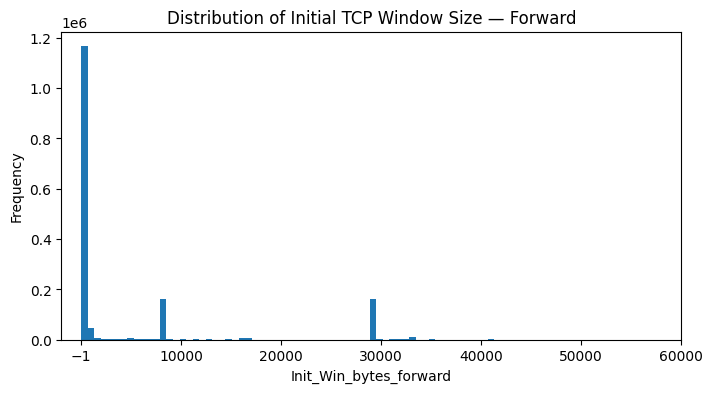

In [19]:
# visualizing both features
plt.figure(figsize=(8, 4))
plt.hist(train_df["Init_Win_bytes_forward"], bins=100)
plt.xlim(-2000, 60000)
plt.xticks([-1, 10000, 20000, 30000, 40000, 50000, 60000])
plt.title("Distribution of Initial TCP Window Size — Forward")
plt.xlabel("Init_Win_bytes_forward")
plt.ylabel("Frequency")
plt.show()

In [20]:
display(pd.DataFrame(train_df["Init_Win_bytes_backward"].value_counts().head(10)))

,count
Init_Win_bytes_backward,
-1,890054
235,176858
0,44666
33304,17933
256,16351
229,14776
60,13750
32832,12890
31,11494


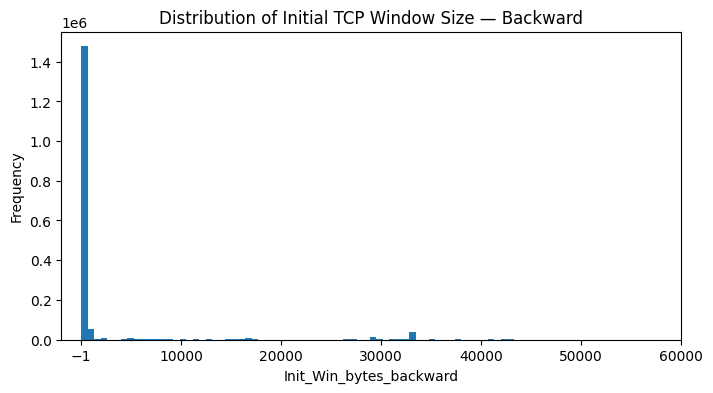

In [21]:
# Dostribution plot for the feature
plt.figure(figsize=(8, 4))
plt.hist(train_df["Init_Win_bytes_backward"], bins=100)
plt.xlim(-2000, 60000)
plt.xticks([-1, 10000, 20000, 30000, 40000, 50000, 60000])
plt.title("Distribution of Initial TCP Window Size — Backward")
plt.xlabel("Init_Win_bytes_backward")
plt.ylabel("Frequency")
plt.show()

As per the above output, it is evident that -1 is a frequent, systematic value in features **Init_Win_bytes_backward** and **Init_Win_bytes_forward**; thus, we will not treat these values as ordinary negative measurements and will keep them for now.

Next, we will remove the rows with negative values in the features 
1. Flow IAT Min,
2. Flow Duration,
3. Flow Packets/s,
4. Flow IAT Mean,
5. Flow IAT Max,
6. Fwd Header Length,
7. min_seg_size_forward,
8. Flow Bytes/s,
9. Bwd Header Length,
10. Fwd IAT Min.                  


In [22]:
negative_value_features = [
    "Flow IAT Min",
    "Flow Duration",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Max",
    "Fwd Header Length",
    "min_seg_size_forward",
    "Flow Bytes/s",
    "Bwd Header Length",
    "Fwd IAT Min"
]

train_df = train_df[(train_df[negative_value_features] >=0).all(axis=1)]

In [23]:
# sanity check for negative numbers
negative_count = (train_df[numeric_cols] < 0).sum()
negative_count = pd.DataFrame(negative_count[negative_count > 0])
display(negative_count)

,0
Init_Win_bytes_forward,627832
Init_Win_bytes_backward,890010


Next we will handle the inf values present in some columns:

In [24]:
inf_counts = np.isinf(train_df.select_dtypes(include="number")).sum()
inf_counts = inf_counts[inf_counts > 0]

display(inf_counts)

Flow Bytes/s      725
Flow Packets/s    725
dtype: int64

Since, the number of observations with inf values in columns Flow Bytes/s and Flow Packets/s is relatively low, we will remove the rows with inf values in these columns.

In [25]:
inf_mask = np.isinf(train_df[["Flow Bytes/s", "Flow Packets/s"]]).any(axis=1)
train_df = train_df[~inf_mask].copy()

In [26]:
discrete_numerical_features = [
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets",
    "Fwd Packet Length Max",
    "Fwd Packet Length Min",
    "Bwd Packet Length Max",
    "Bwd Packet Length Min",
    "Flow IAT Max",
    "Flow IAT Min",
    "Fwd IAT Total",
    "Fwd IAT Max",
    "Fwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Max",
    "Bwd IAT Min",
    "Fwd PSH Flags",
    "Bwd PSH Flags",
    "Fwd URG Flags",
    "Bwd URG Flags",
    "Fwd Header Length",
    "Bwd Header Length",
    "Min Packet Length",
    "Max Packet Length",
    "FIN Flag Count",
    "SYN Flag Count",
    "RST Flag Count",
    "PSH Flag Count",
    "ACK Flag Count",
    "URG Flag Count",
    "CWE Flag Count",
    "ECE Flag Count",
    "Down/Up Ratio",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate",
    "Subflow Fwd Packets",
    "Subflow Fwd Bytes",
    "Subflow Bwd Packets",
    "Subflow Bwd Bytes",
    "Init_Win_bytes_forward",
    "Init_Win_bytes_backward",
    "act_data_pkt_fwd",
    "min_seg_size_forward",
    "Active Max",
    "Active Min",
    "Idle Max",
    "Idle Min"
]




continuous_numerical_features = [
    "Flow Duration",
    "Fwd Packet Length Mean",
    "Fwd Packet Length Std",
    "Bwd Packet Length Mean",
    "Bwd Packet Length Std",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Fwd IAT Mean",
    "Fwd IAT Std",
    "Bwd IAT Mean",
    "Bwd IAT Std",
    "Fwd Packets/s",
    "Bwd Packets/s",
    "Packet Length Mean",
    "Packet Length Std",
    "Packet Length Variance",
    "Average Packet Size",
    "Avg Fwd Segment Size",
    "Avg Bwd Segment Size",
    "Active Mean",
    "Active Std",
    "Idle Mean",
    "Idle Std"
]

Verify if we accidently left any feature:

In [27]:
# sanity check 
[col for col in train_df.columns if col not in continuous_numerical_features + discrete_numerical_features]

['Destination Port', 'Fwd Header Length.1', 'Label', 'target']

The output indicates that we have covered all the relevant numerical fatures. Now we will check the distribution for these features.

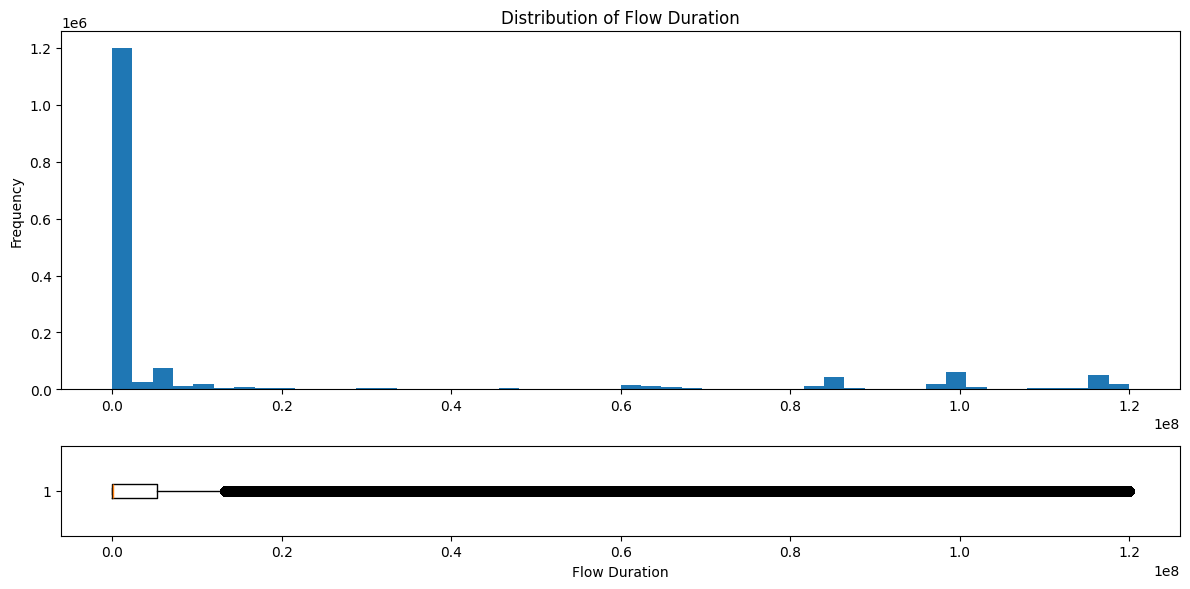

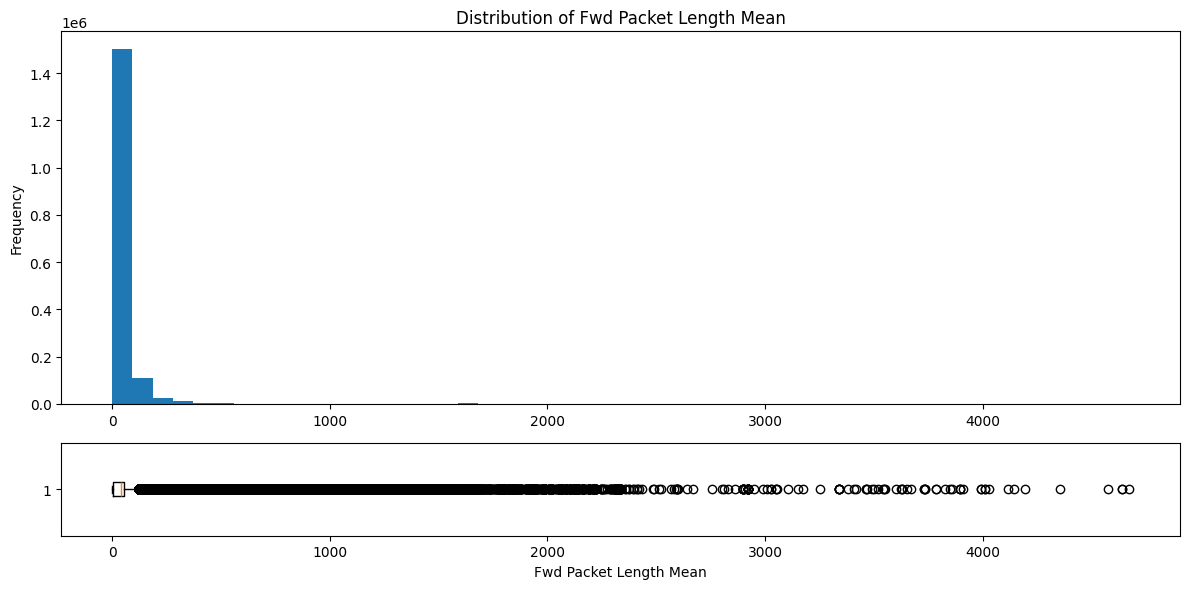

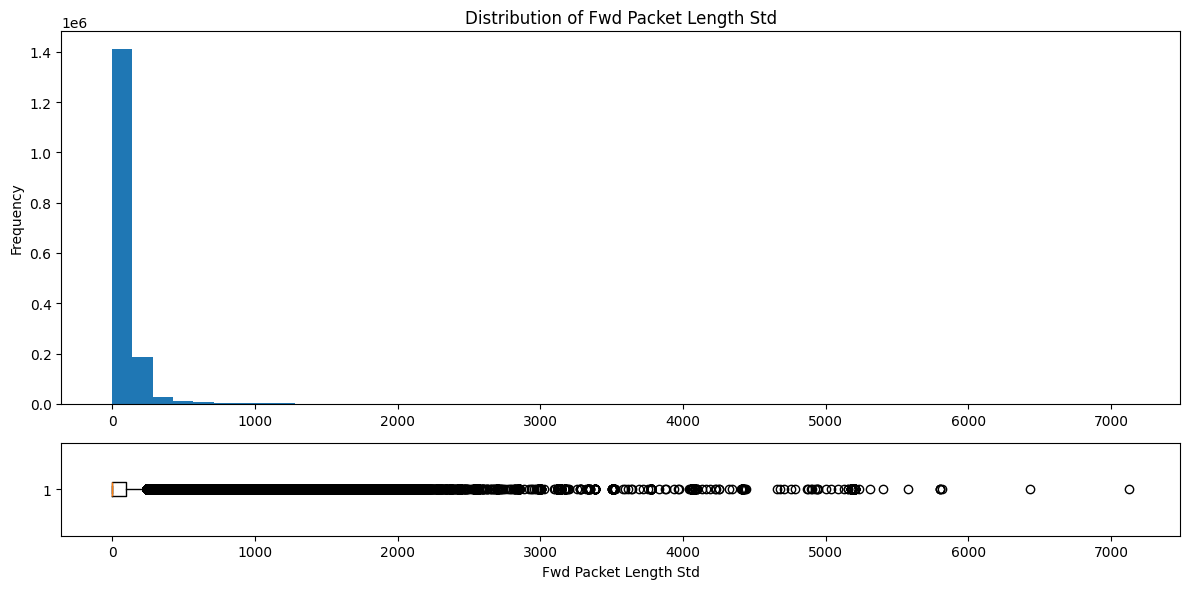

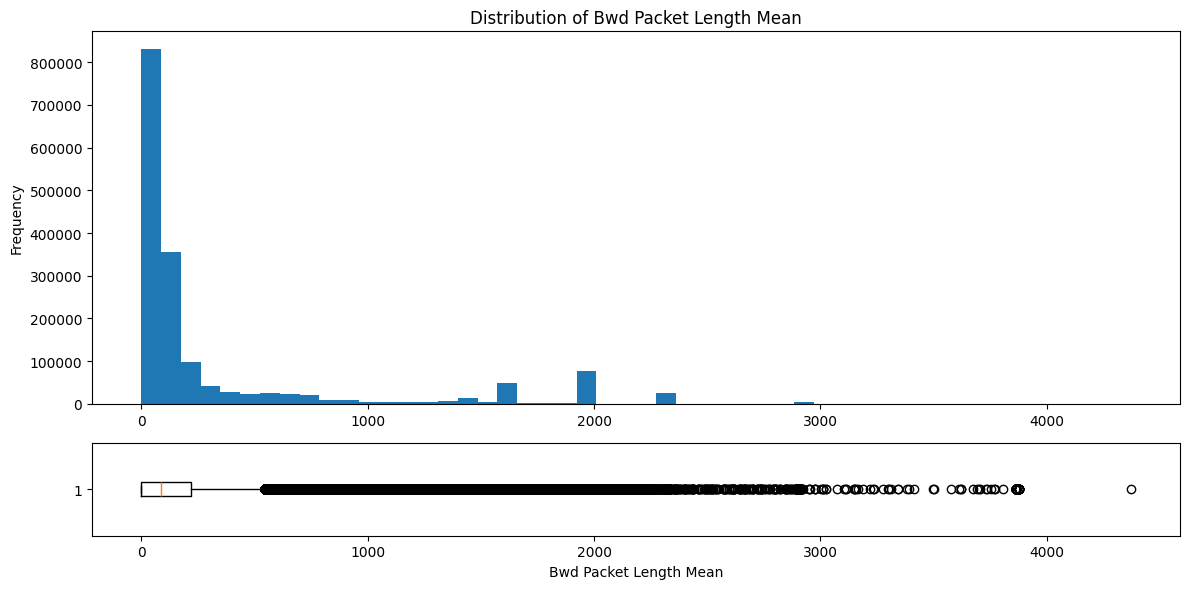

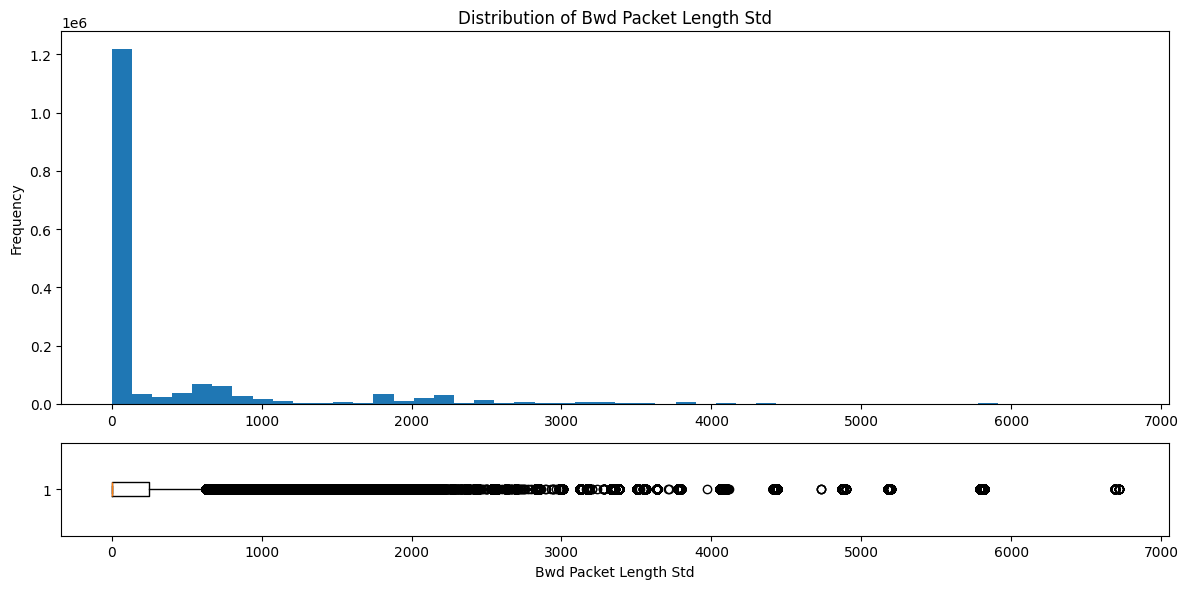

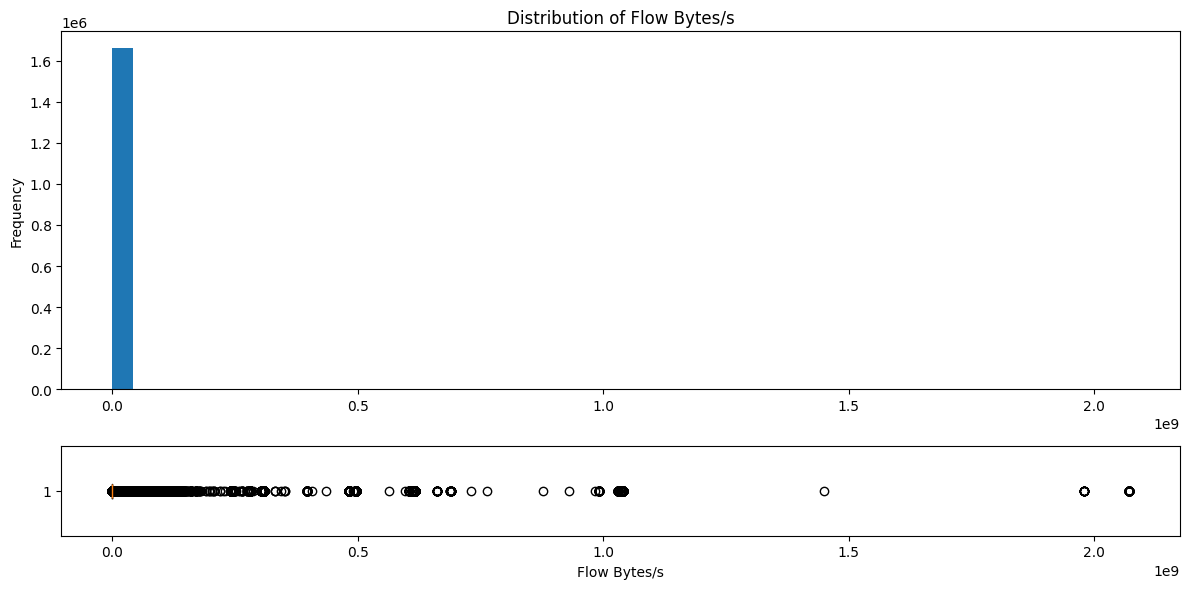

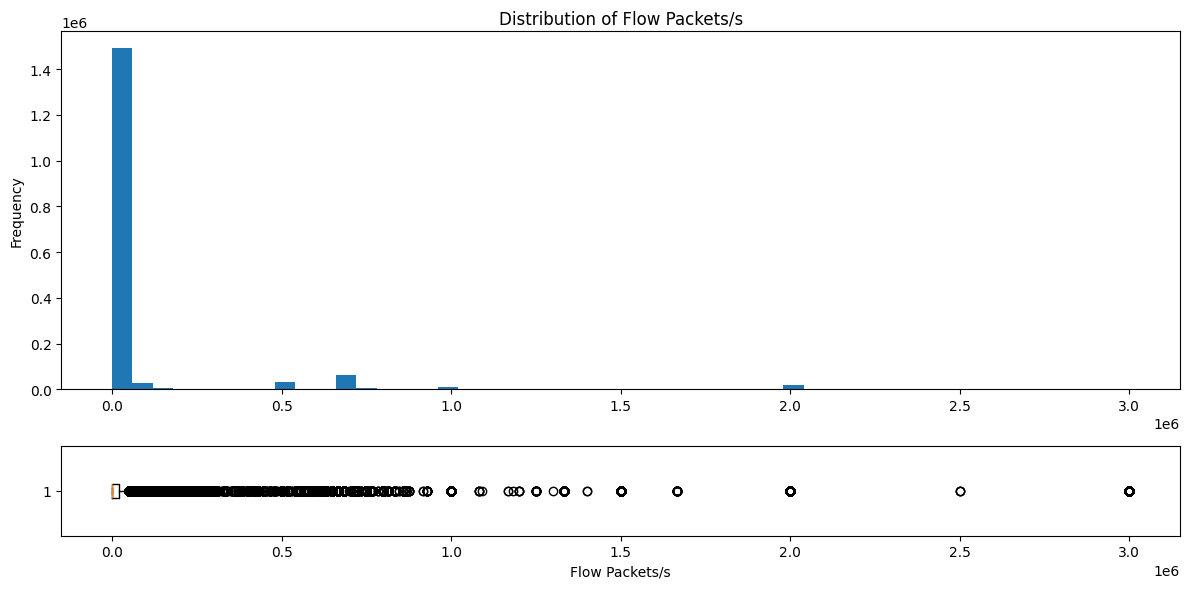

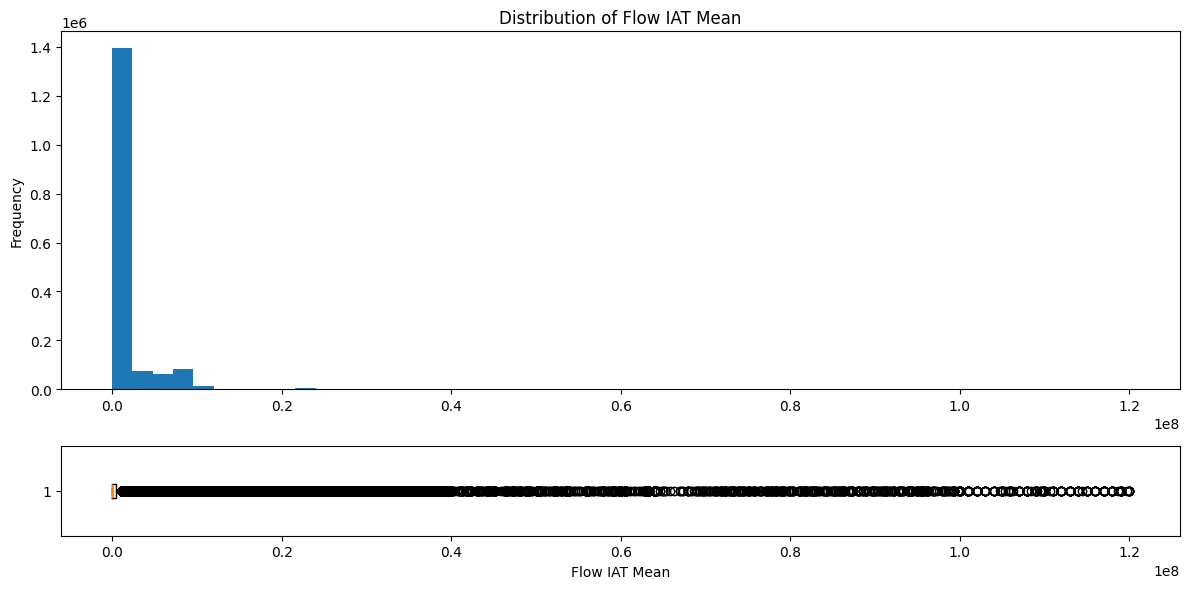

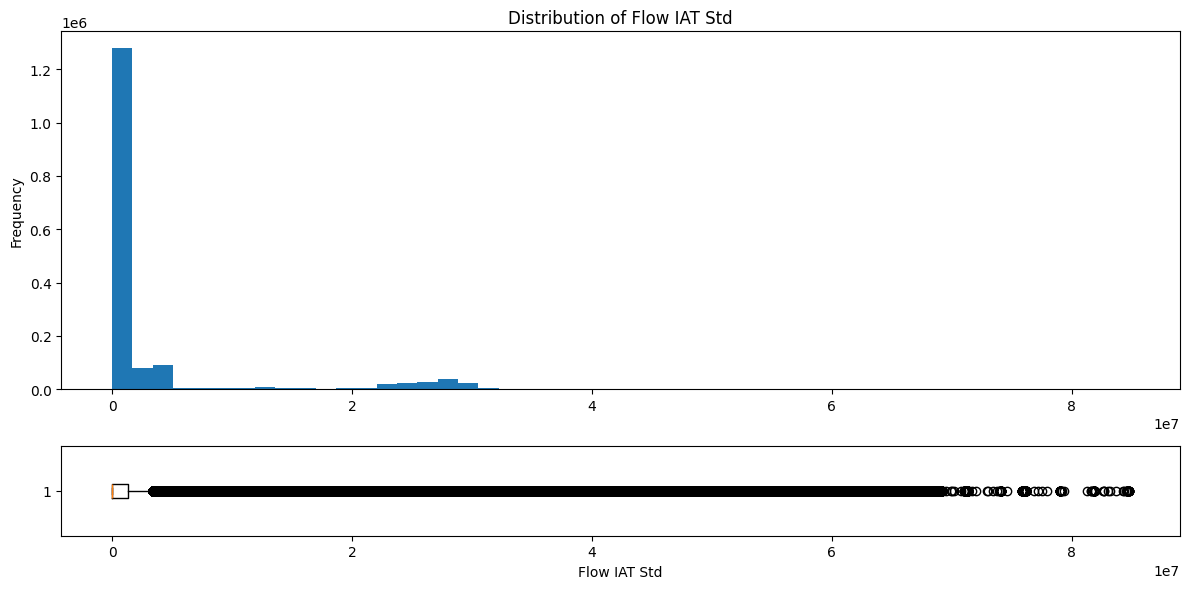

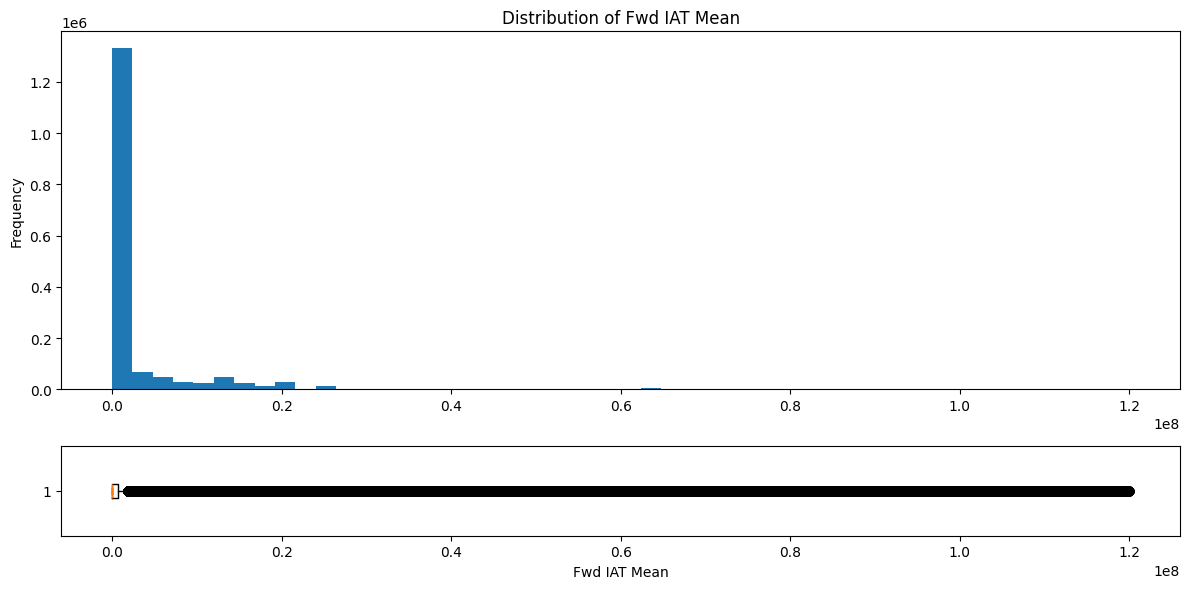

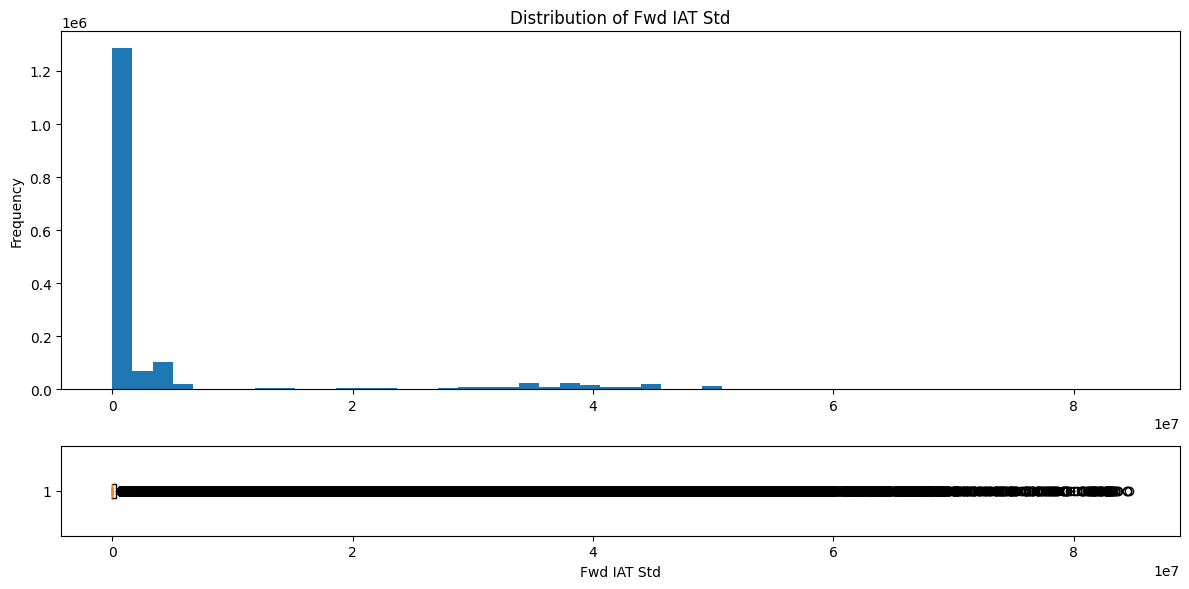

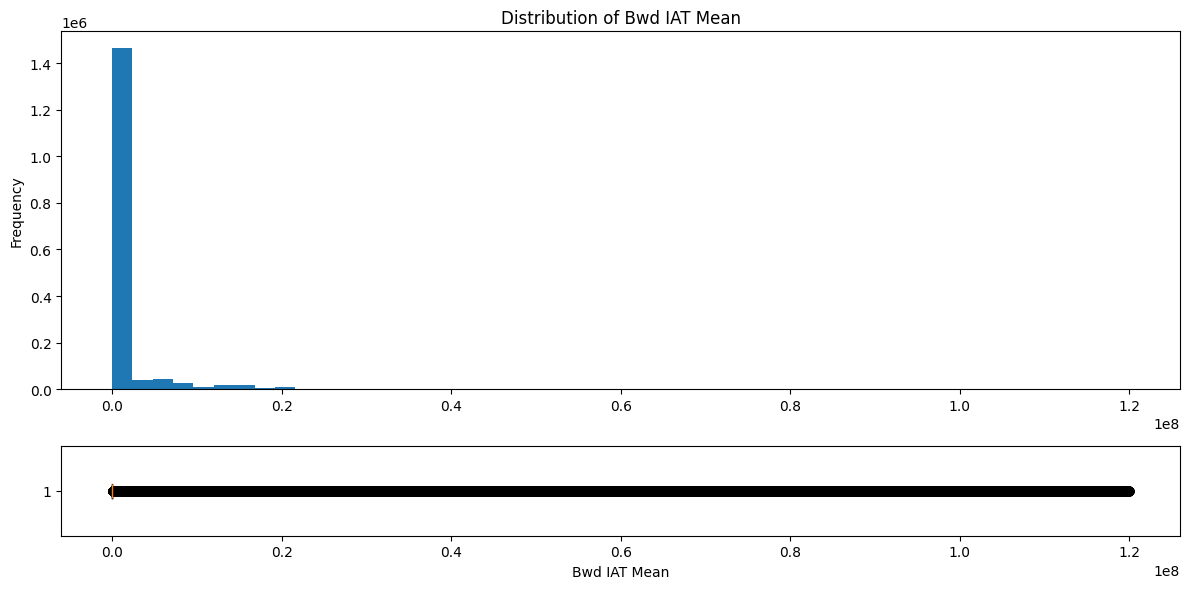

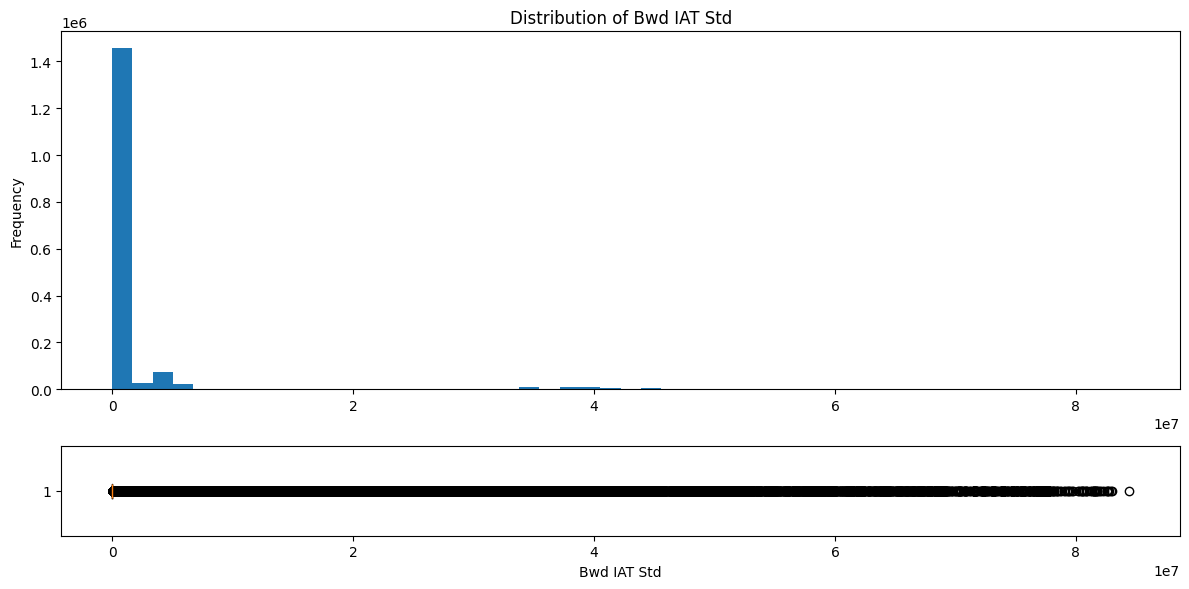

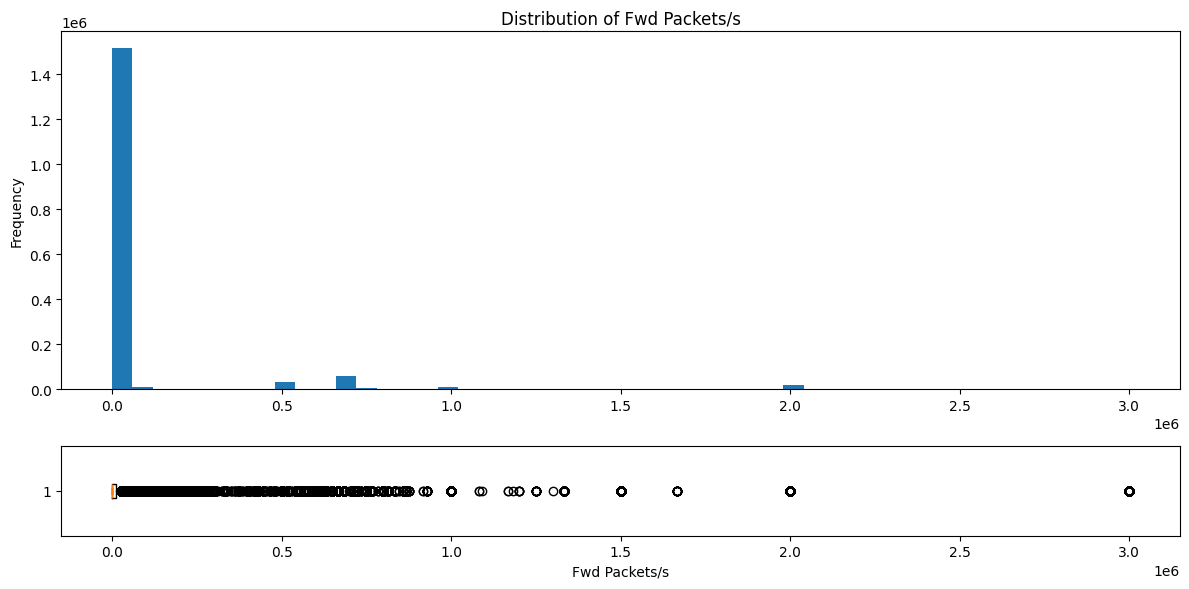

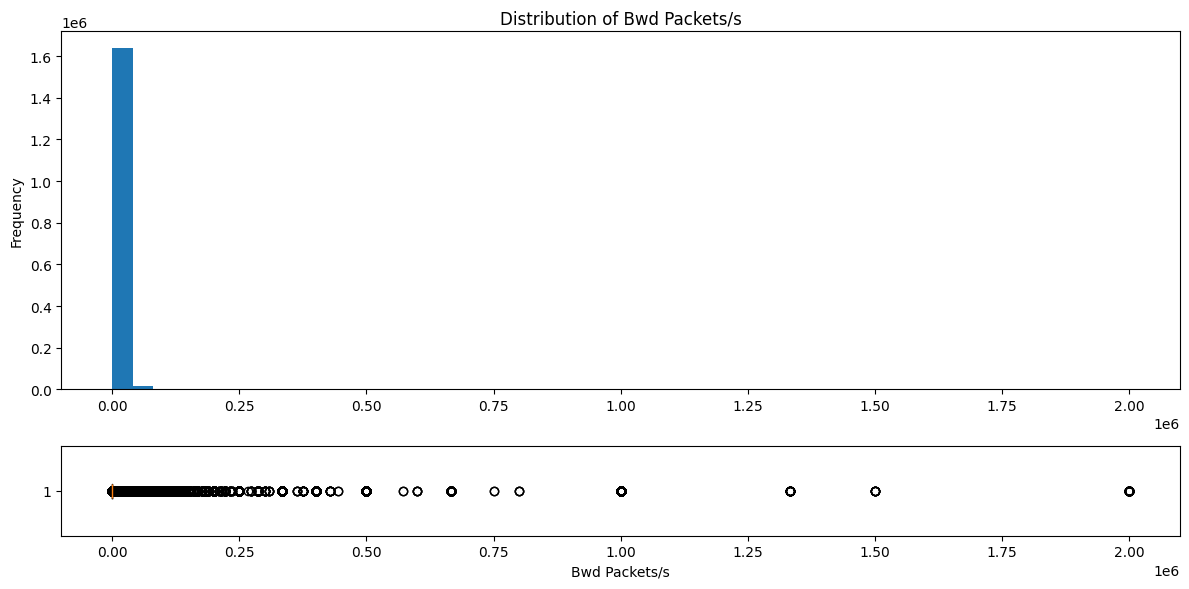

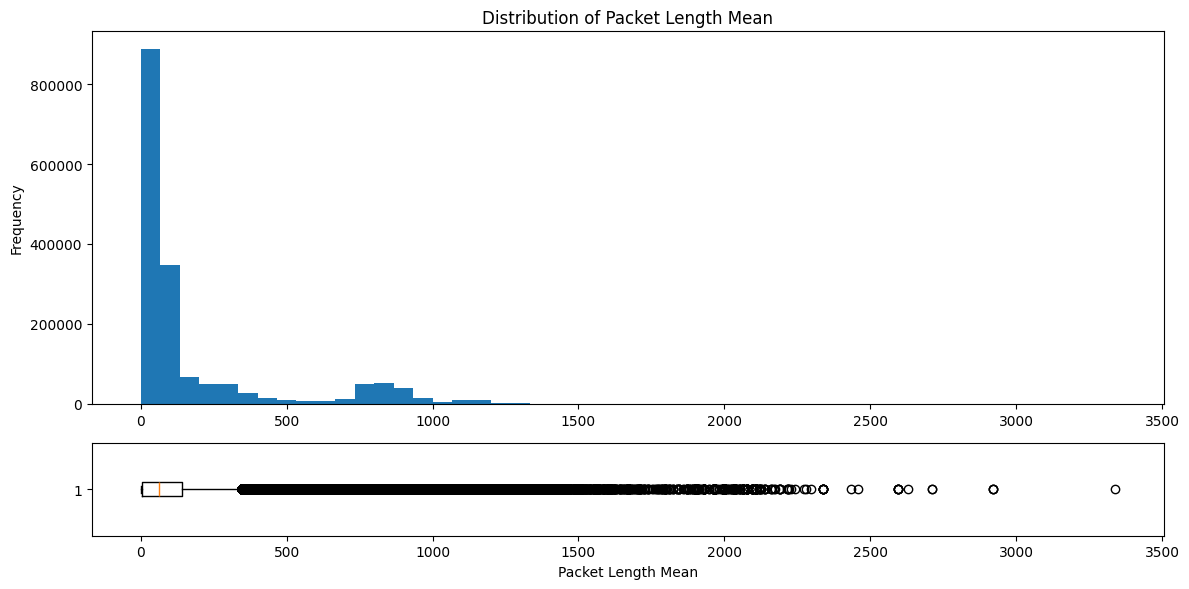

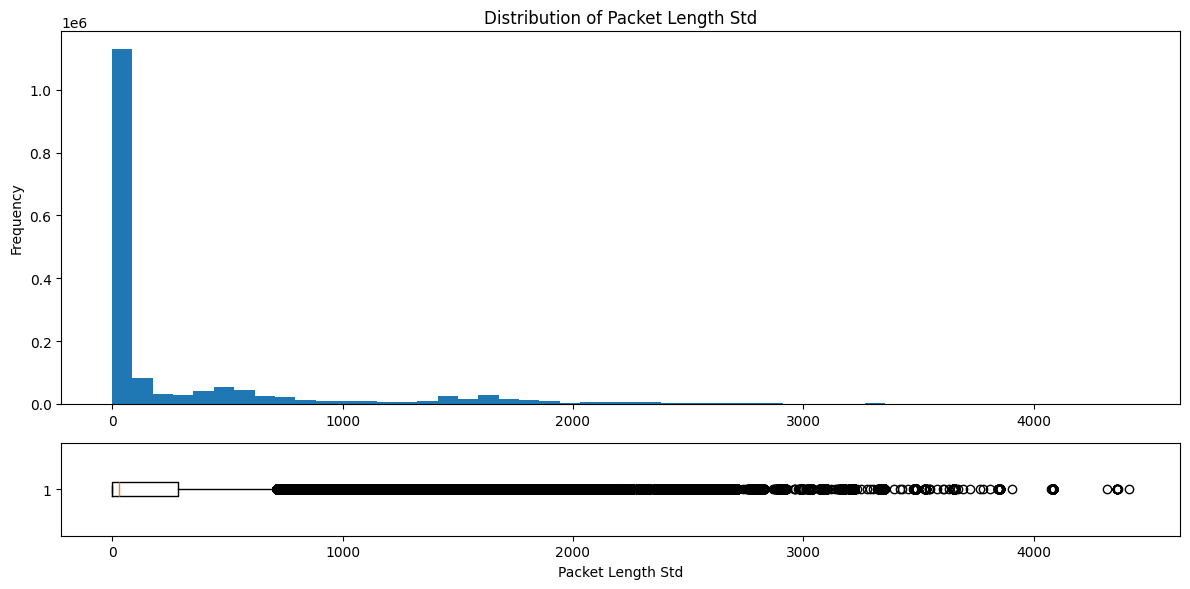

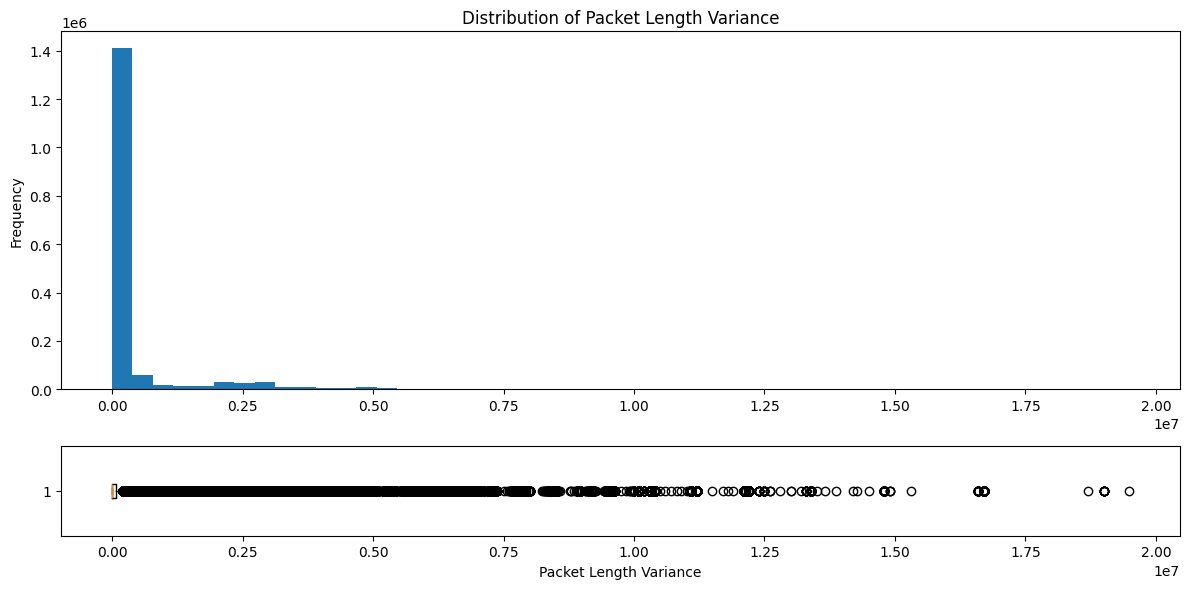

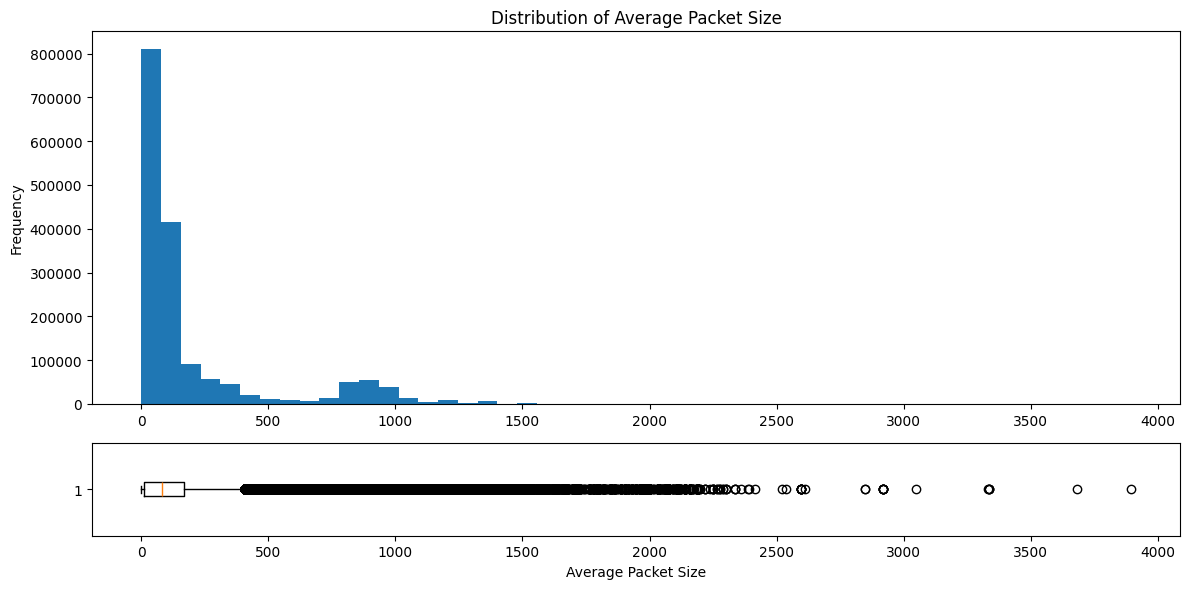

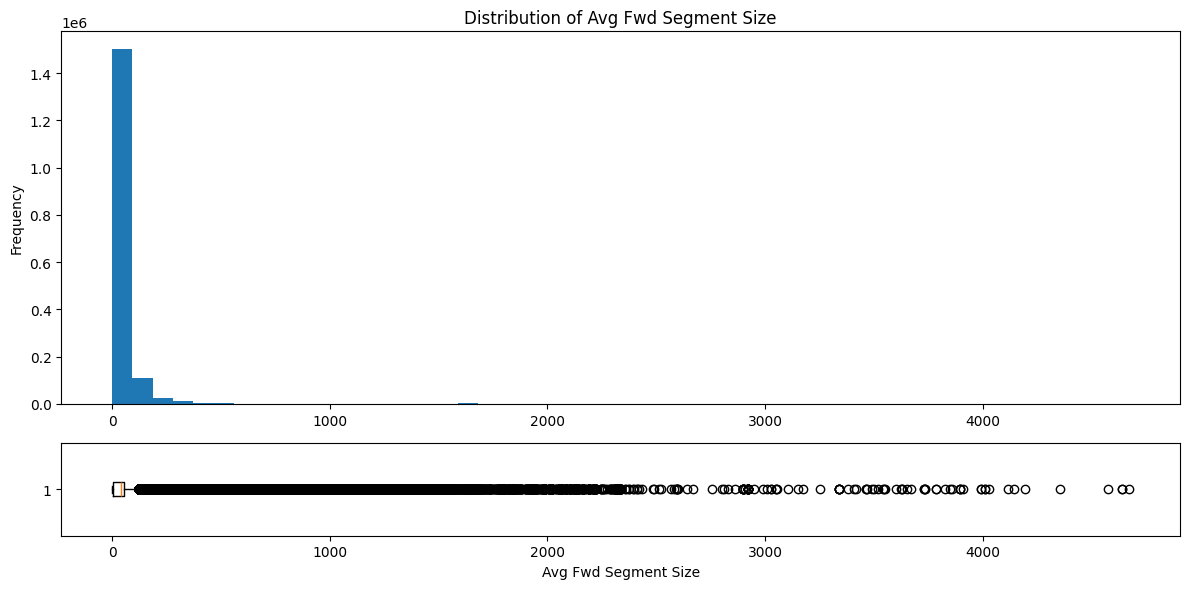

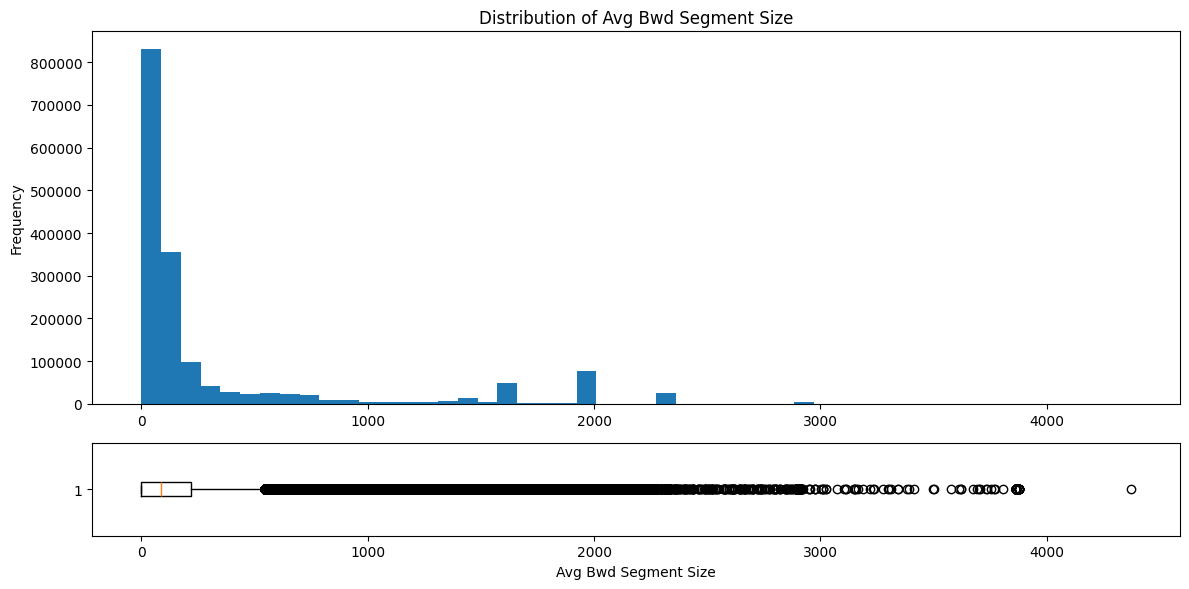

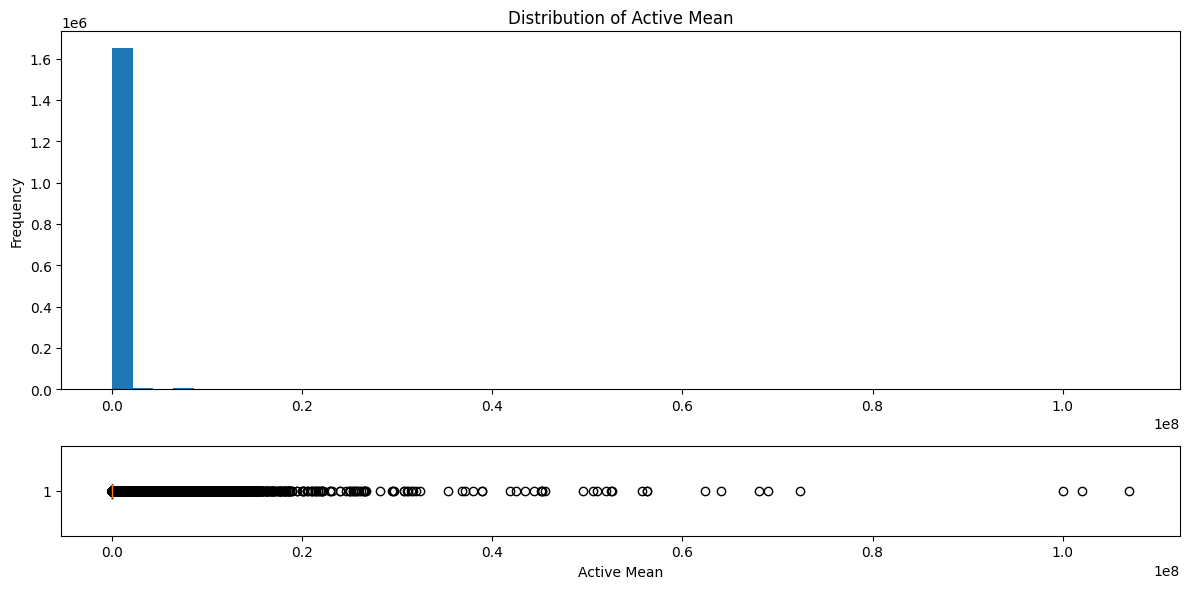

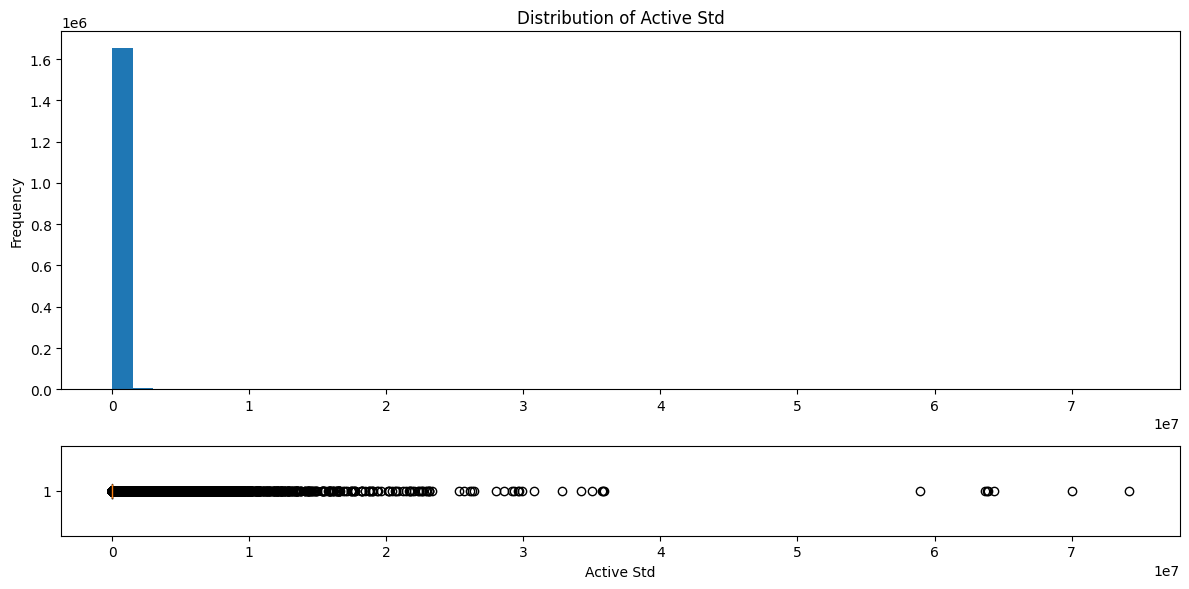

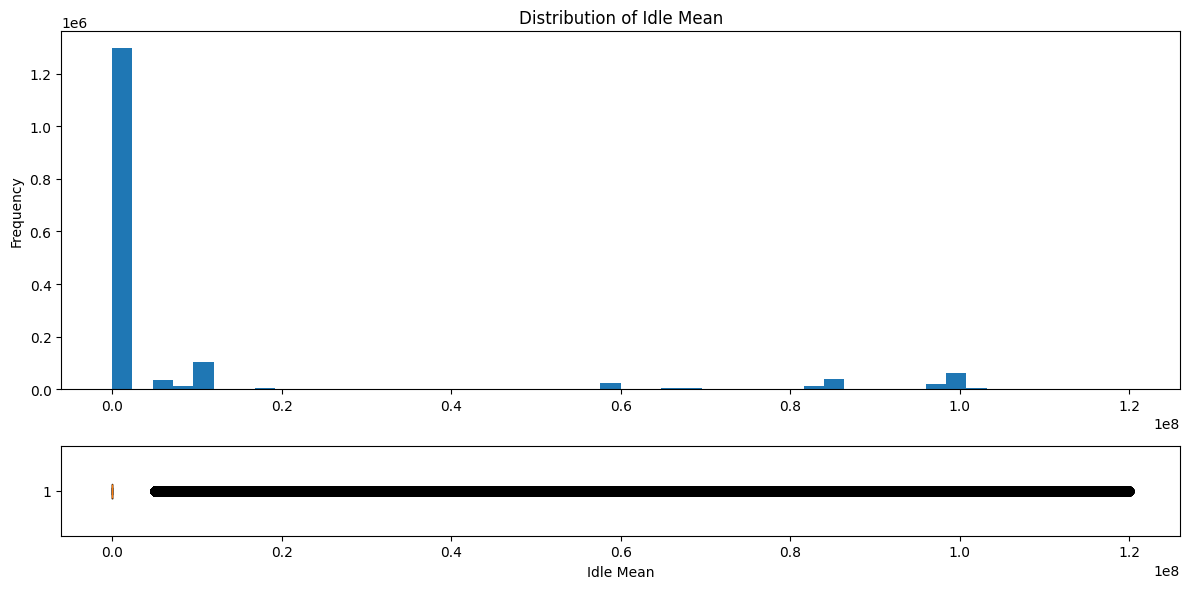

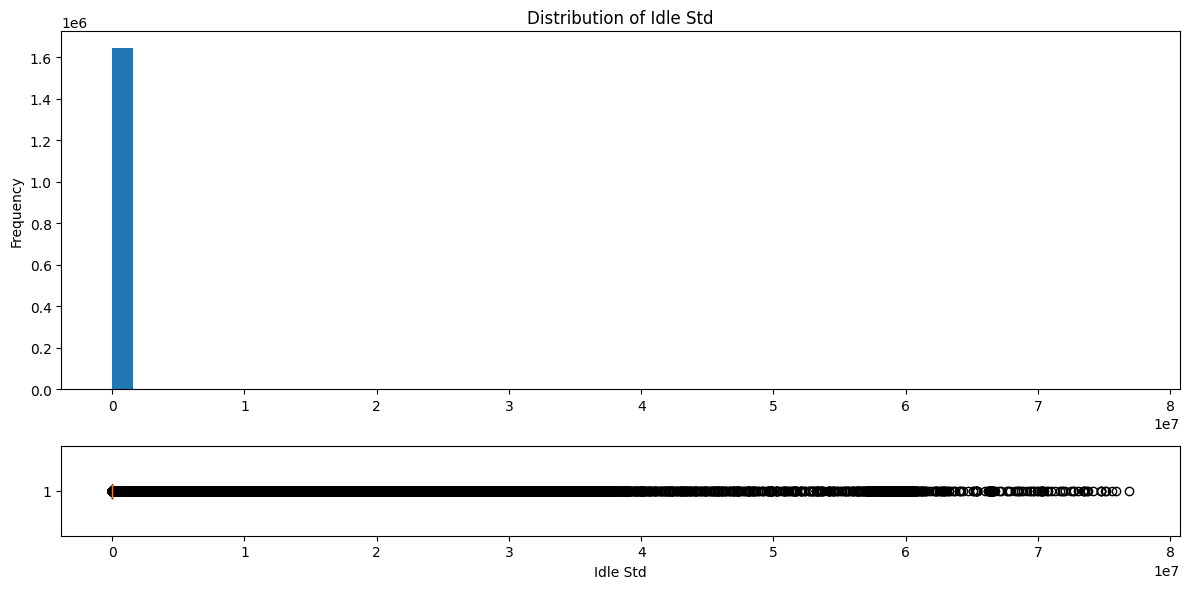

In [28]:
for feature in continuous_numerical_features:

    values = train_df[feature].dropna()

    fig, axes = plt.subplots(
        2, 1,
        figsize=(12, 6),
        gridspec_kw={"height_ratios": [4, 1]}
    )

    # Histogram
    axes[0].hist(values, bins=50)
    axes[0].set_title(f"Distribution of {feature}")
    axes[0].set_ylabel("Frequency")

    # Horizontal box plot
    axes[1].boxplot(
        values,
        vert=False
    )
    axes[1].set_xlabel(feature)

    plt.tight_layout()
    plt.show()

    print(f"\n\n\n")

The plots above show that most continuous numerical features are right-skewed, with more small values and fewer extremely high values. These extreme observations may reflect meaningful network behavior, so we will retain them.

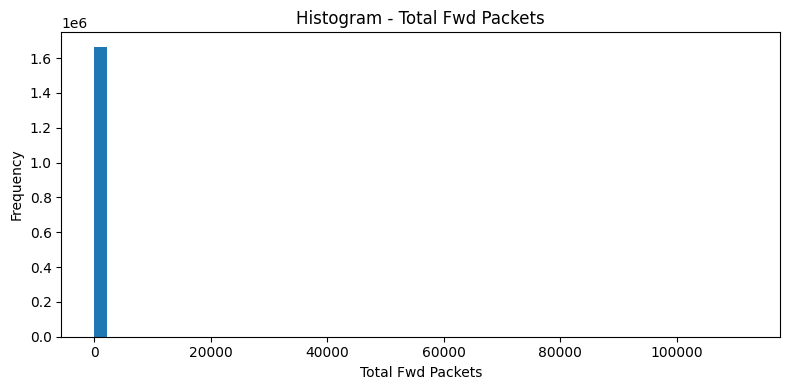

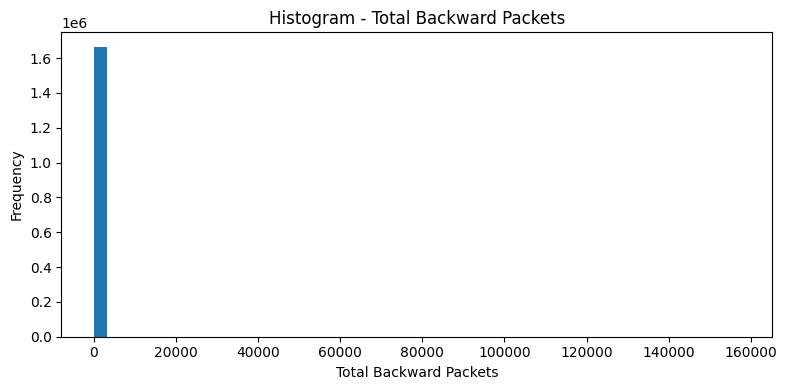

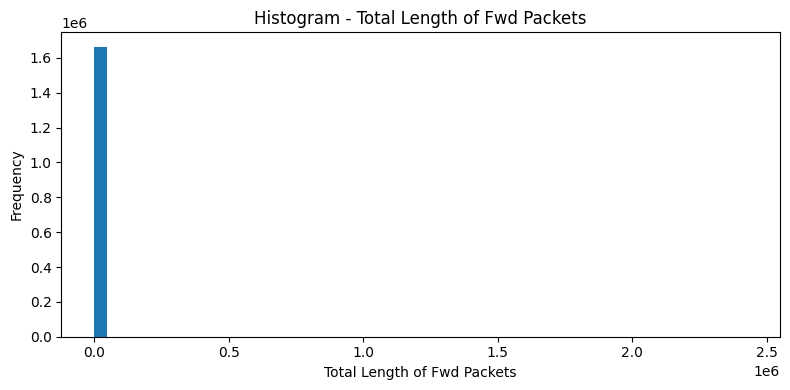

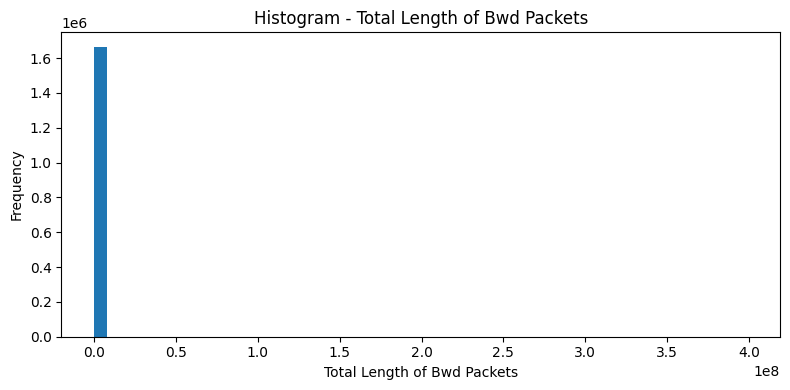

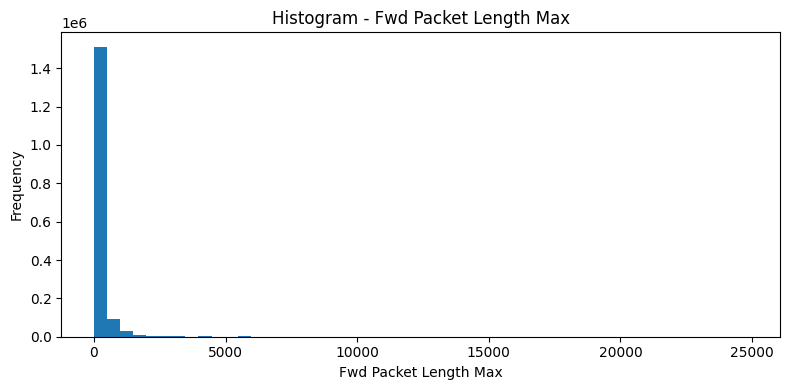

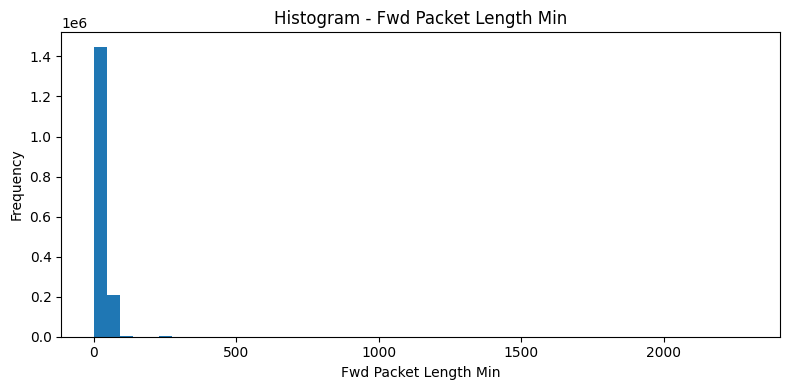

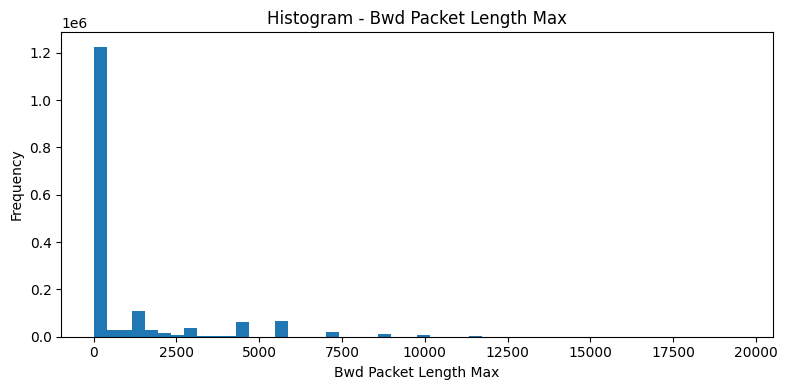

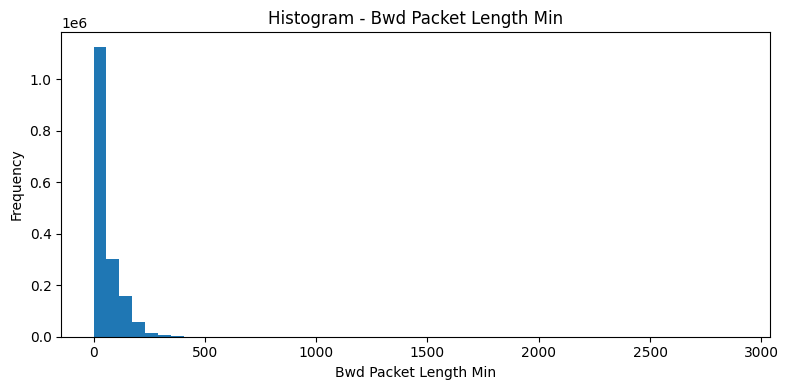

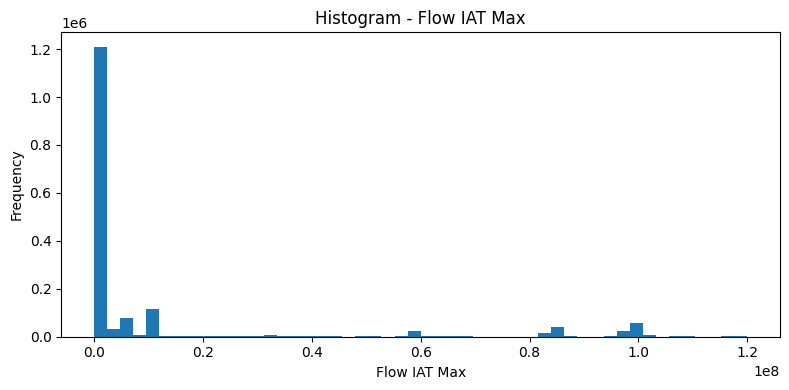

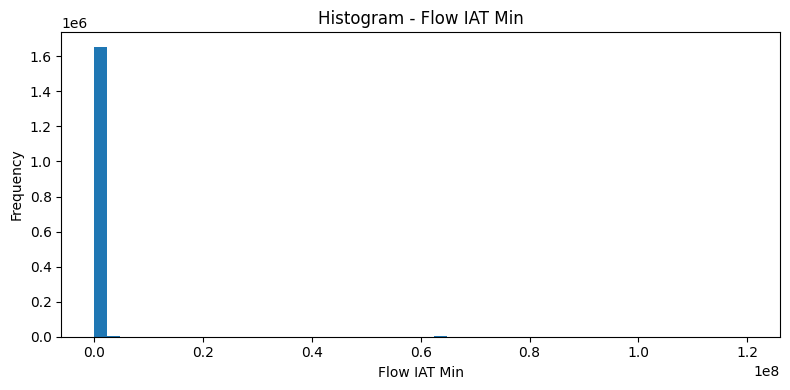

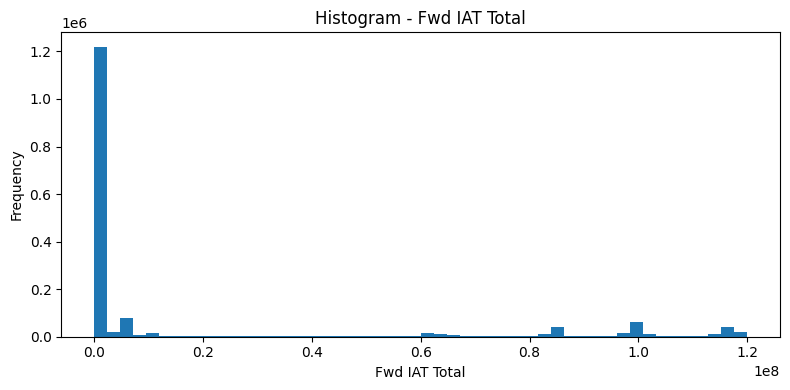

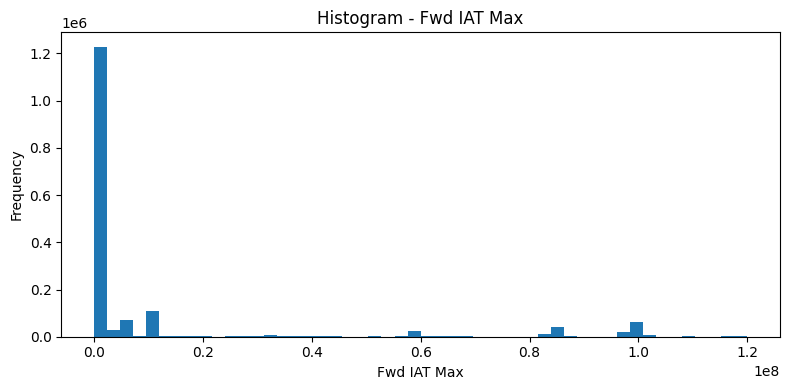

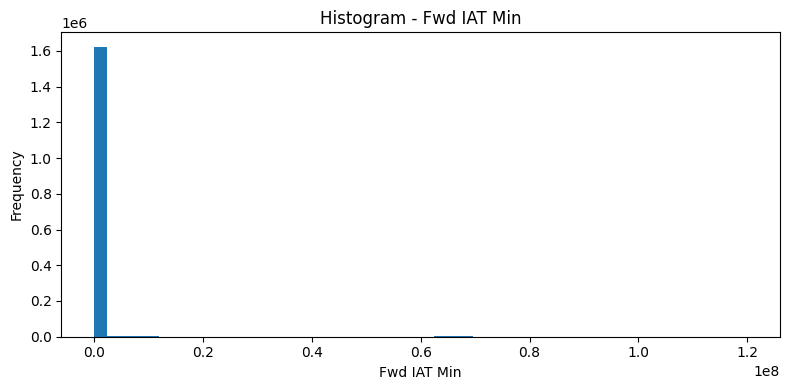

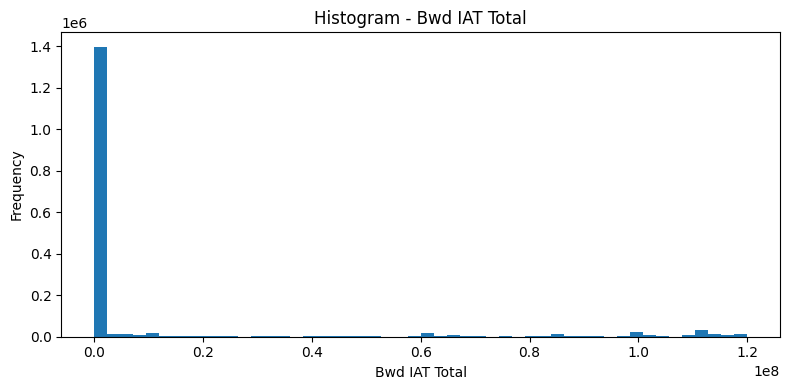

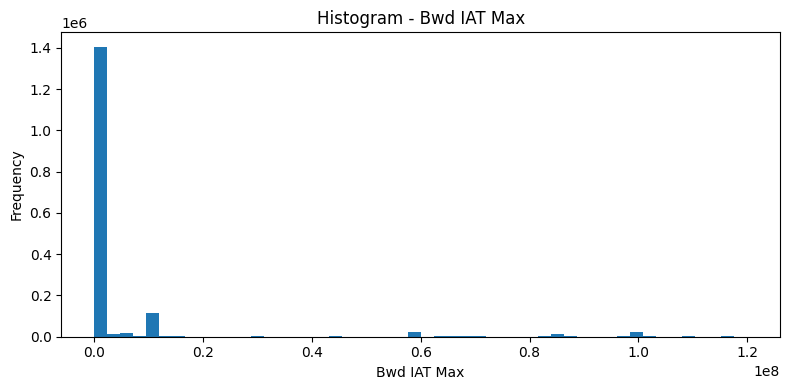

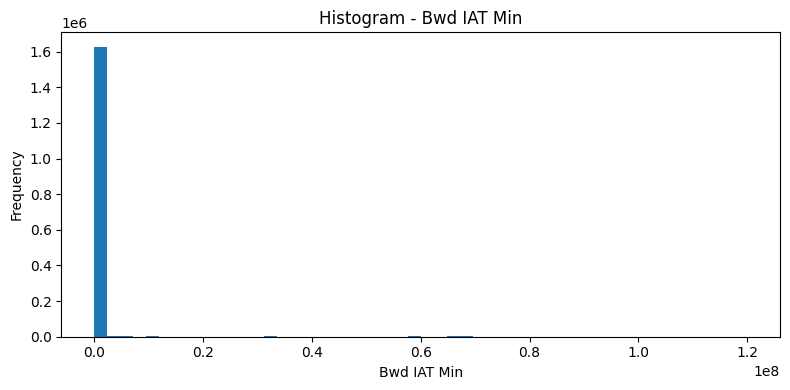

Fwd PSH Flags
0    1574689
1      90043
Name: count, dtype: int64

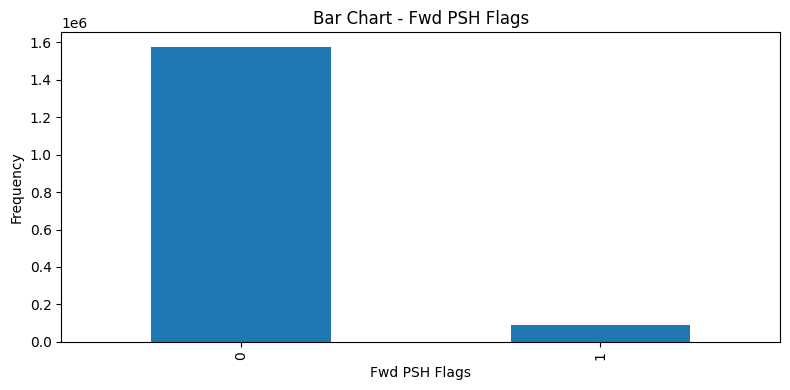

Bwd PSH Flags
0    1664732
Name: count, dtype: int64

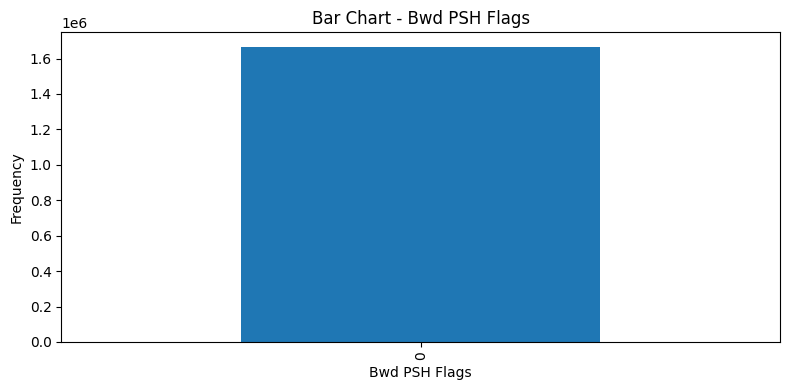

Fwd URG Flags
0    1664732
Name: count, dtype: int64

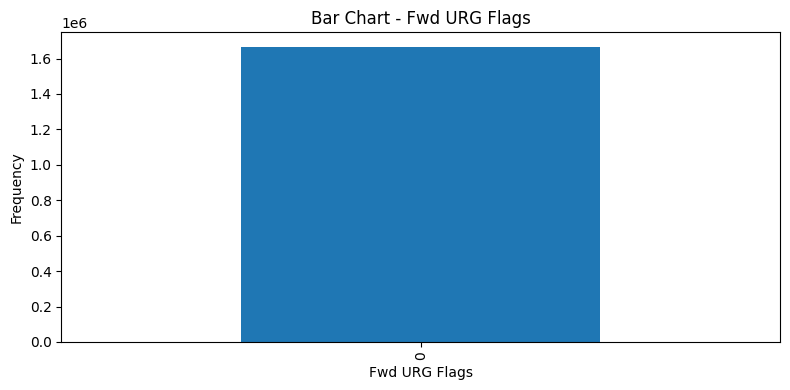

Bwd URG Flags
0    1664732
Name: count, dtype: int64

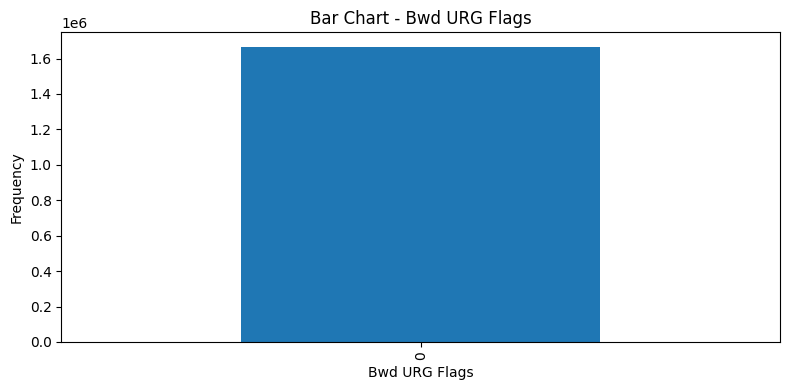

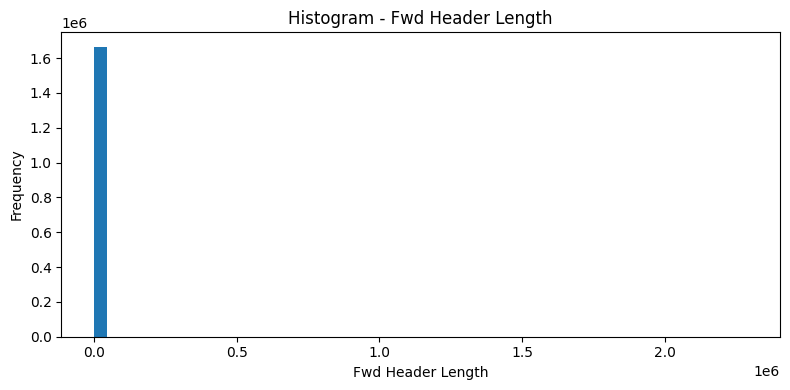

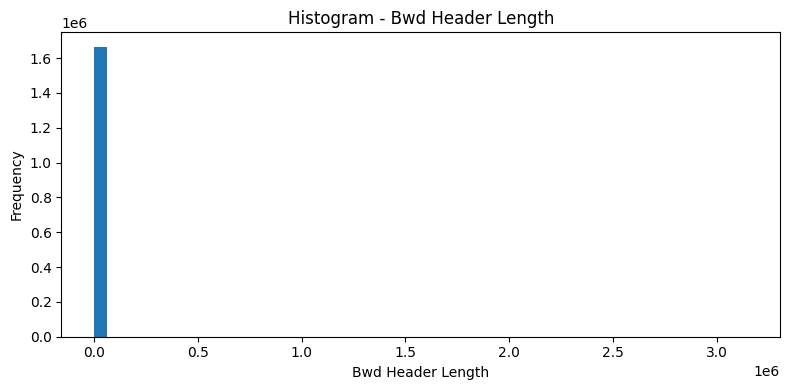

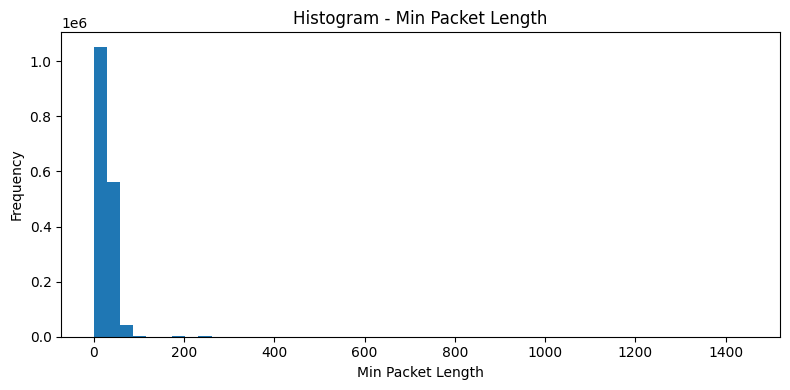

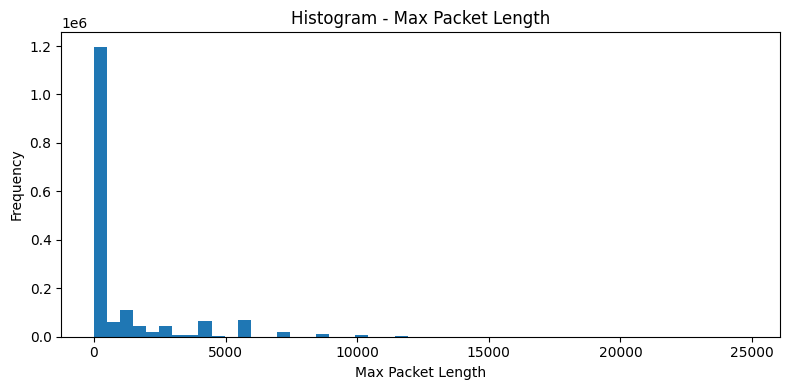

FIN Flag Count
0    1577202
1      87530
Name: count, dtype: int64

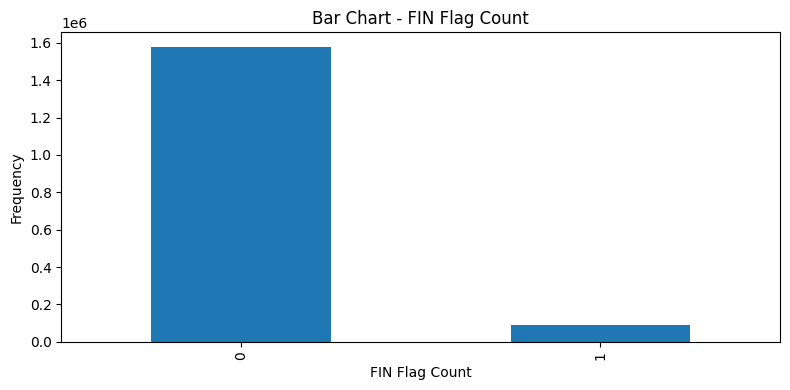

SYN Flag Count
0    1574689
1      90043
Name: count, dtype: int64

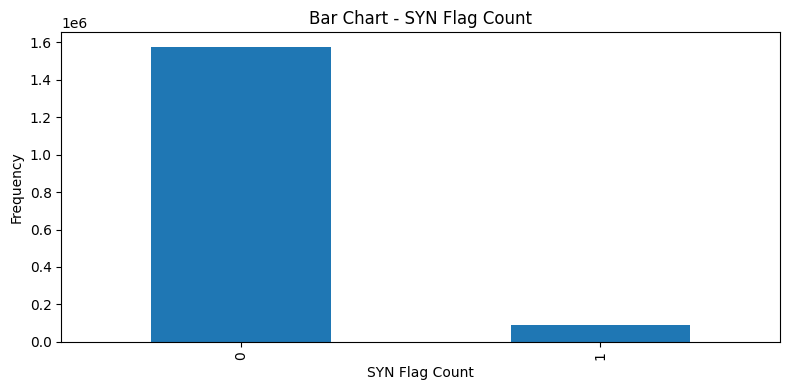

RST Flag Count
0    1664281
1        451
Name: count, dtype: int64

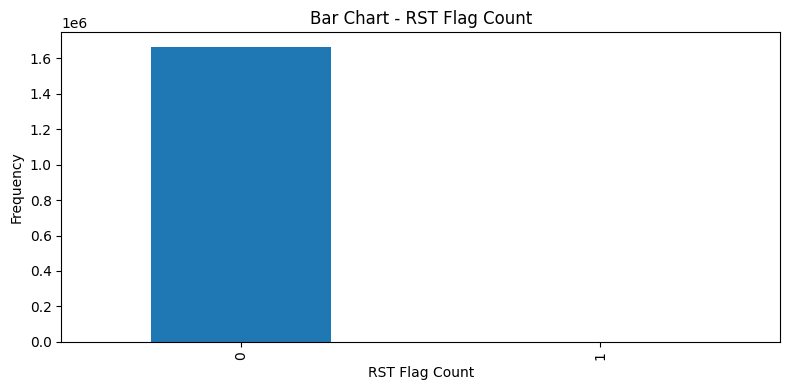

PSH Flag Count
0    1292002
1     372730
Name: count, dtype: int64

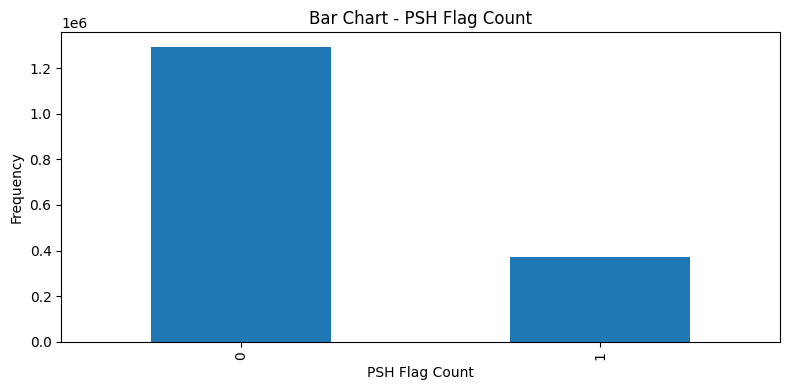

ACK Flag Count
0    1084838
1     579894
Name: count, dtype: int64

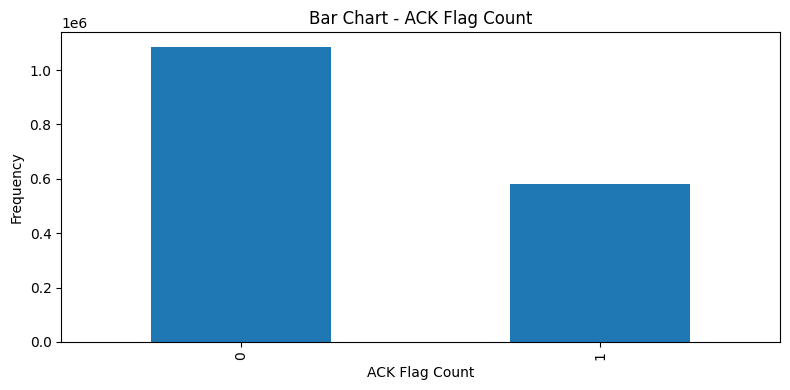

URG Flag Count
0    1504069
1     160663
Name: count, dtype: int64

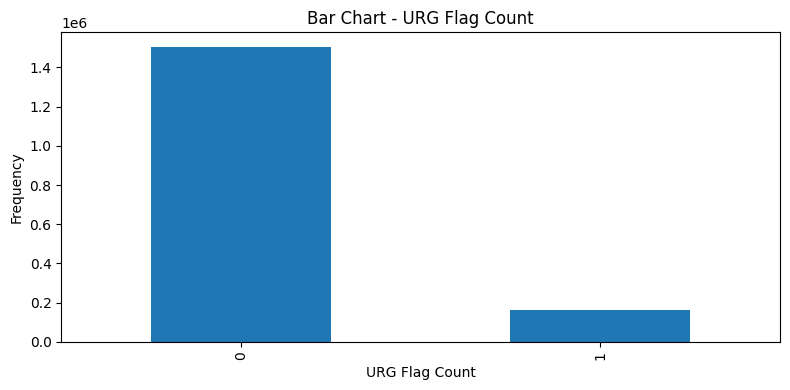

CWE Flag Count
0    1664732
Name: count, dtype: int64

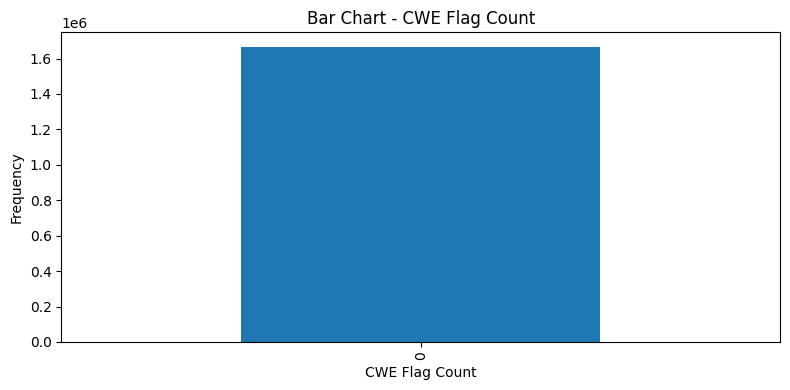

ECE Flag Count
0    1664278
1        454
Name: count, dtype: int64

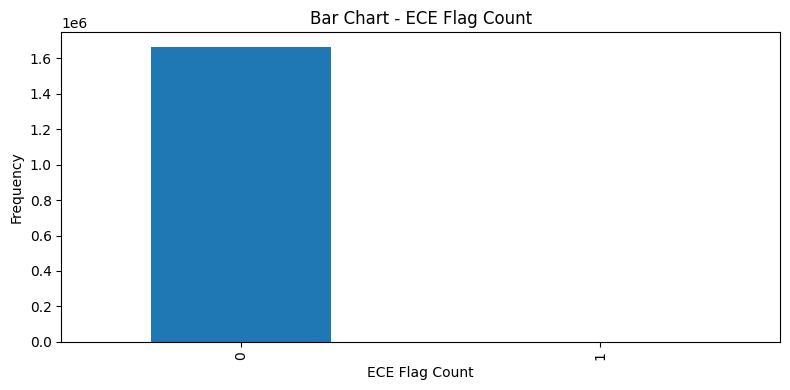

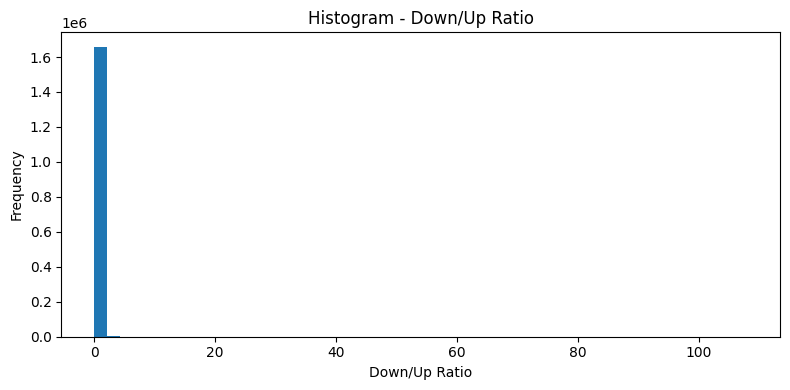

Fwd Avg Bytes/Bulk
0    1664732
Name: count, dtype: int64

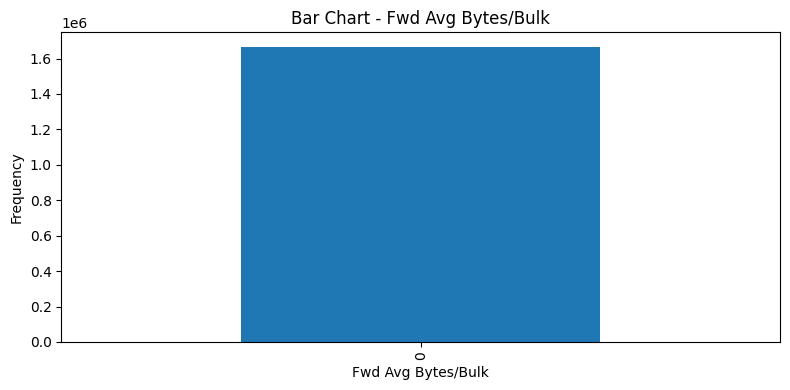

Fwd Avg Packets/Bulk
0    1664732
Name: count, dtype: int64

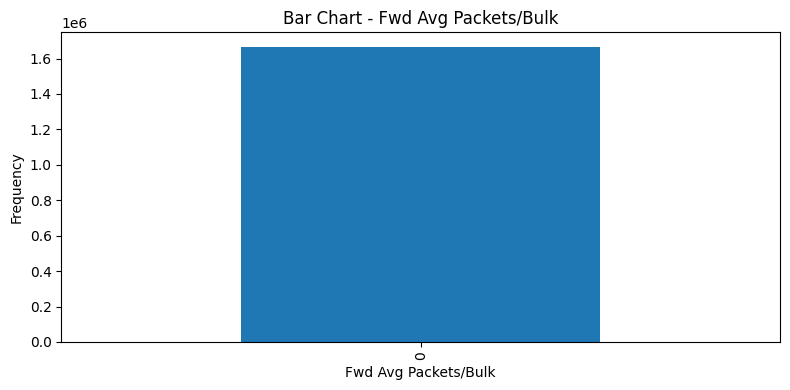

Fwd Avg Bulk Rate
0    1664732
Name: count, dtype: int64

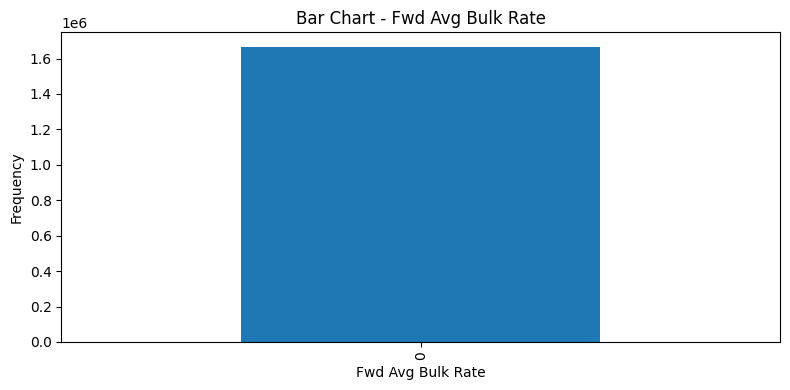

Bwd Avg Bytes/Bulk
0    1664732
Name: count, dtype: int64

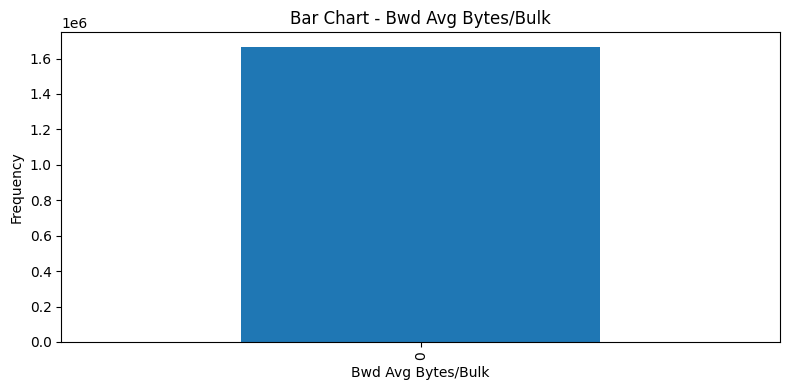

Bwd Avg Packets/Bulk
0    1664732
Name: count, dtype: int64

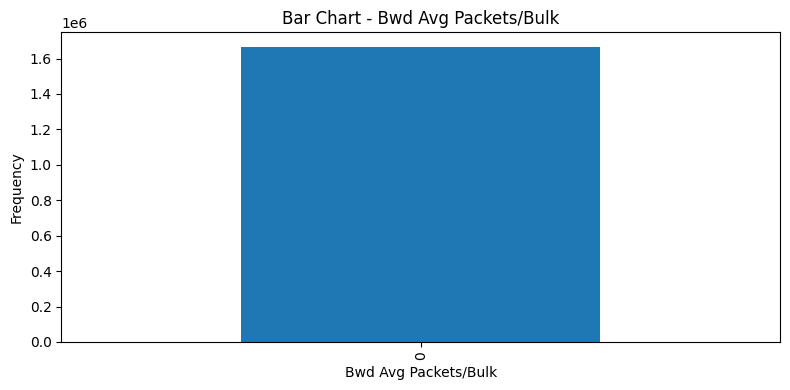

Bwd Avg Bulk Rate
0    1664732
Name: count, dtype: int64

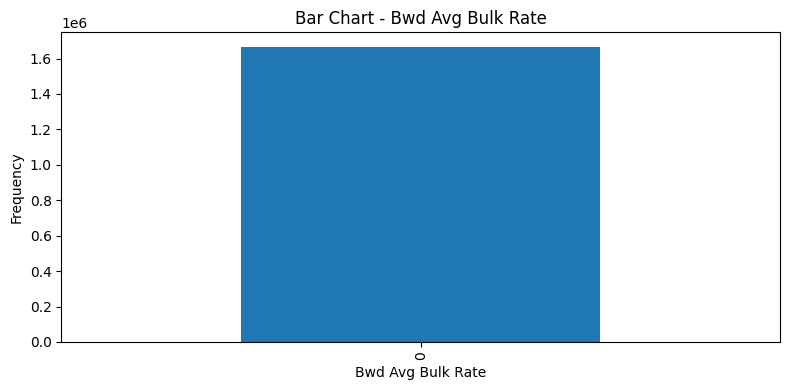

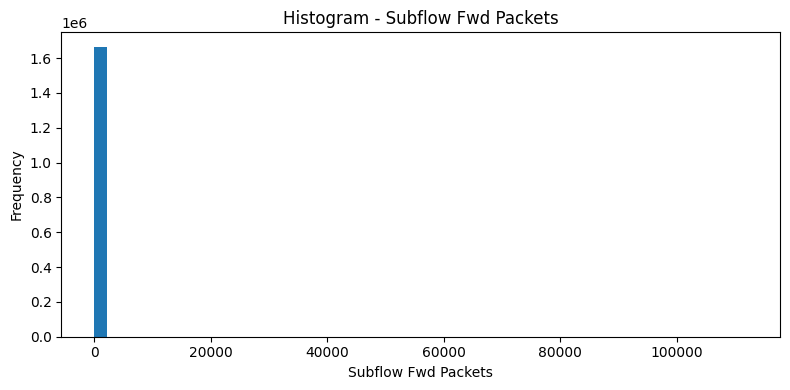

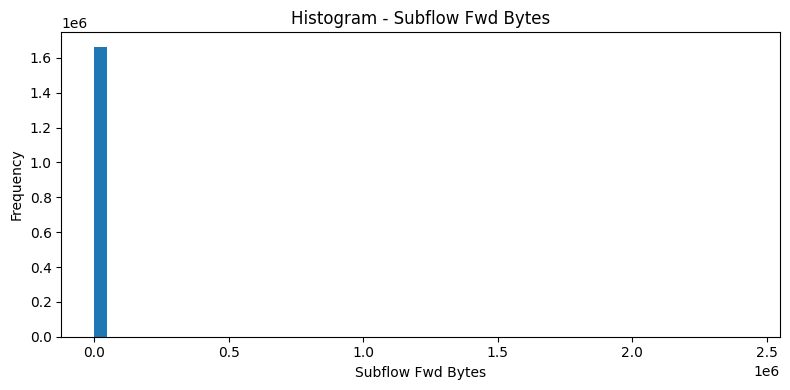

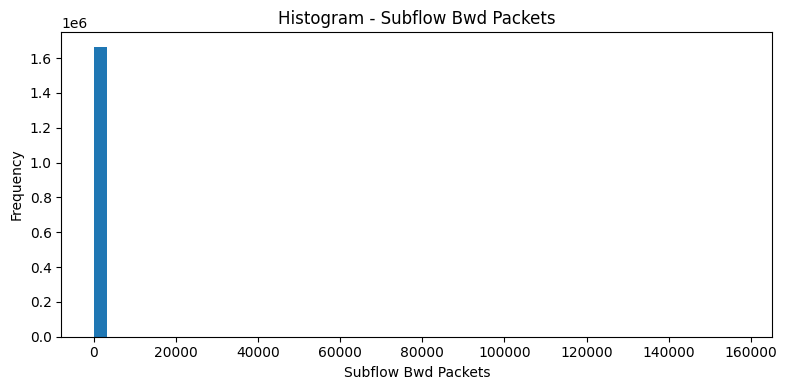

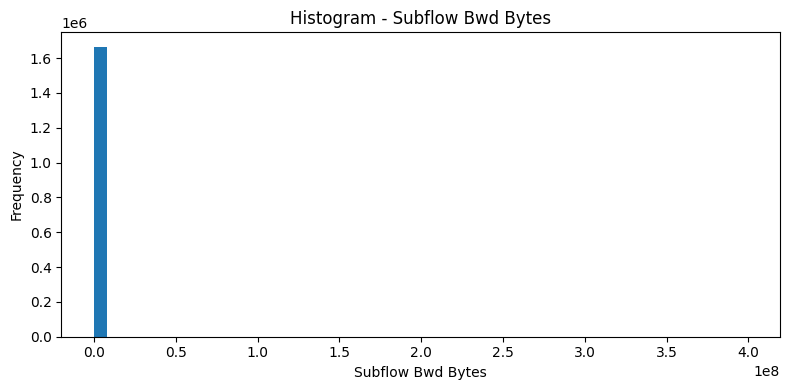

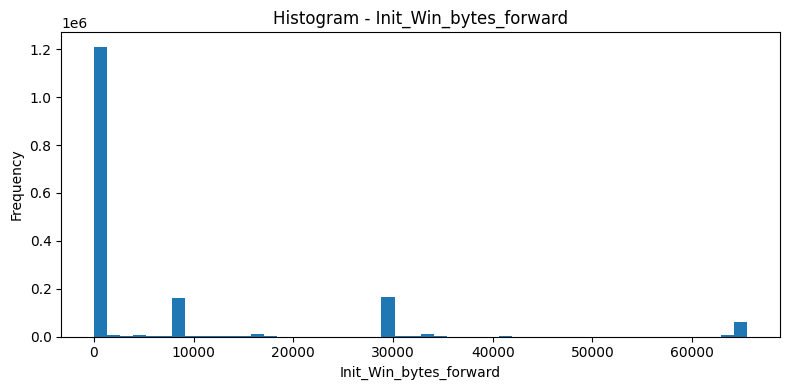

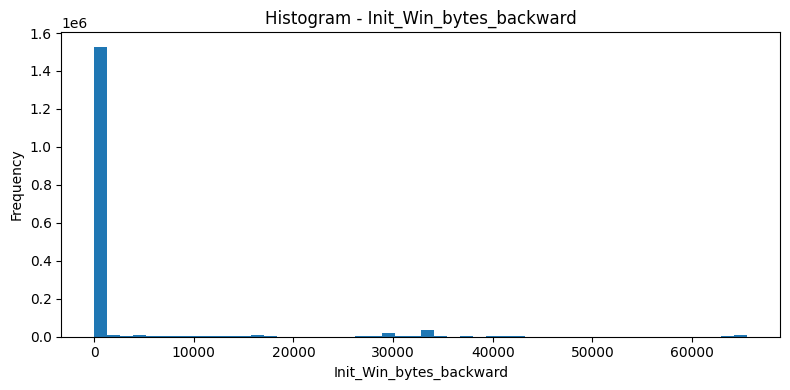

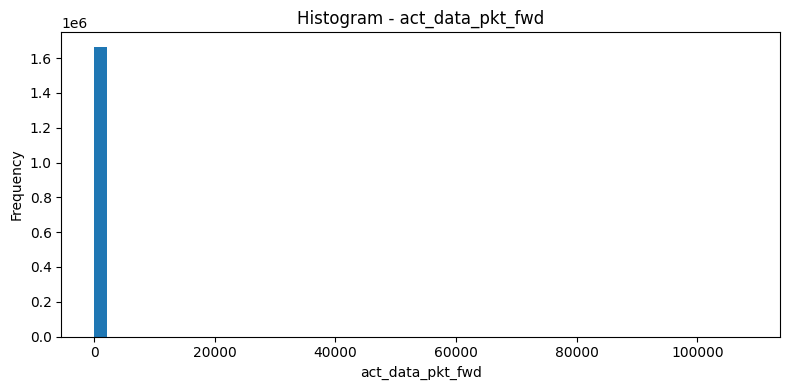

min_seg_size_forward
0        1040
8          23
12          6
14          7
20     799797
24         50
28       1807
32     821223
36          3
40      34178
44       6360
48         56
52         42
56         85
60         44
78          4
93          4
126         1
138         2
Name: count, dtype: int64

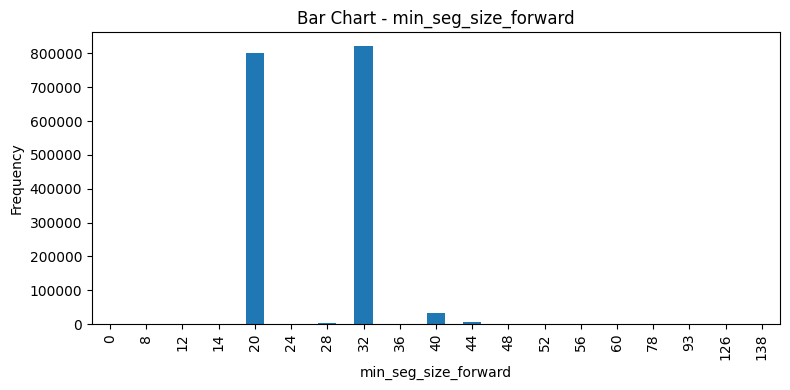

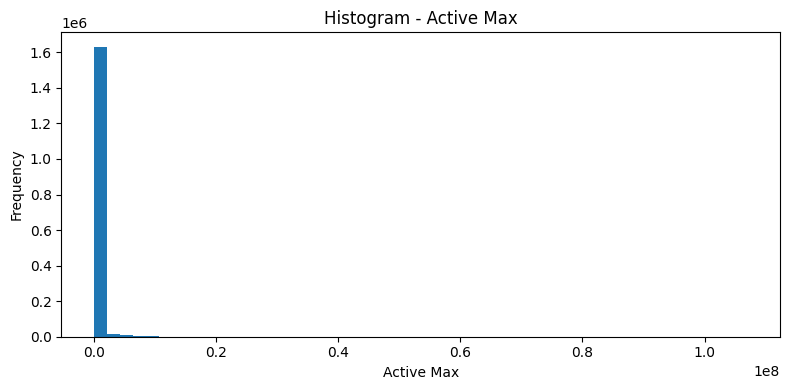

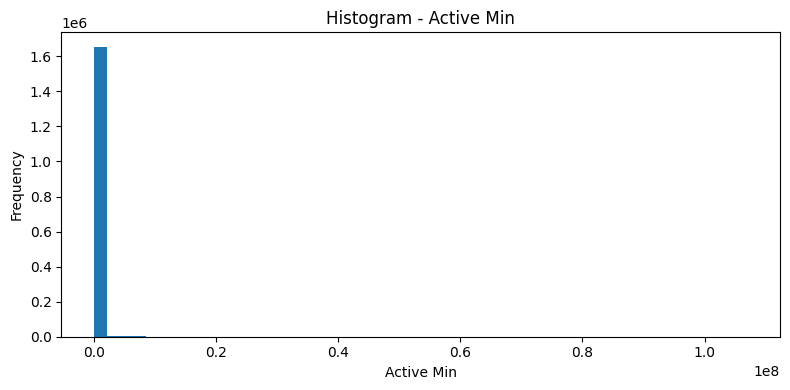

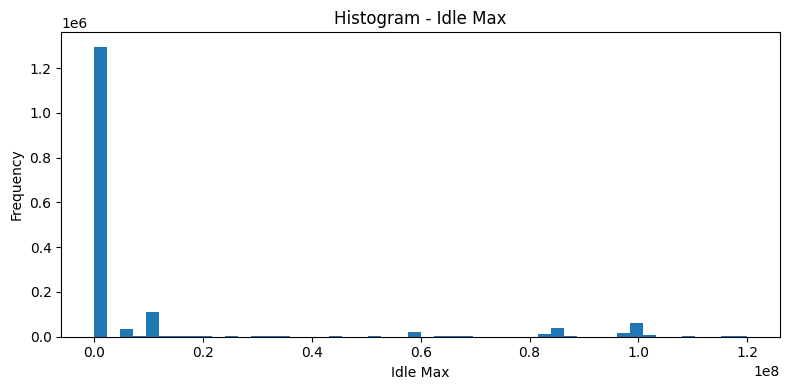

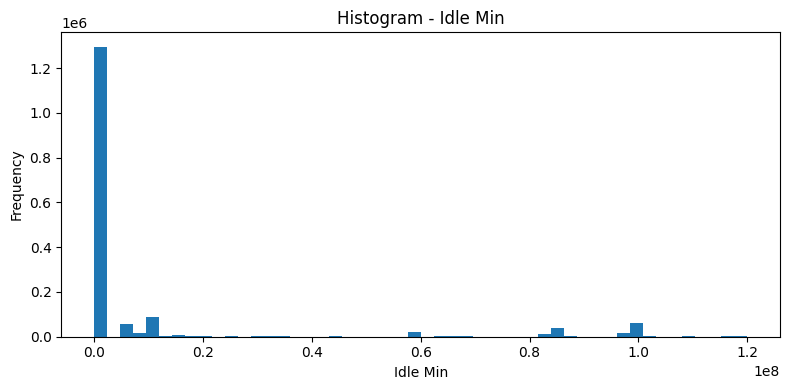

In [29]:
for feature in discrete_numerical_features:

    values = train_df[feature].dropna()
    unique_count = values.nunique()


    if unique_count <= 20:
        

        # Bar chart for low-cardinality discrete features
        counts = values.value_counts().sort_index()

        display(counts)

        plt.figure(figsize=(8, 4))
        counts.plot(kind="bar")
        plt.title(f"Bar Chart - {feature}")
        plt.xlabel(feature)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()


    else:

        # Histogram for high-cardinality discrete features
        plt.figure(figsize=(8, 4))
        plt.hist(values, bins=50)
        plt.title(f"Histogram - {feature}")
        plt.xlabel(feature)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()


We saw that there are multiple features with zero-only values in them. We will exmine those features next:

In [30]:
zero_only_features = train_df.drop(columns="target").columns[
    (train_df.drop(columns="target") == 0).all()
]

In [31]:
print(f" Total Features with zero-only values : {len(zero_only_features)}\n  Feature names: \n{zero_only_features}")

 Total Features with zero-only values : 10
  Feature names: 
Index(['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count',
       'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate',
       'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'],
      dtype='object')


We will drop these feature because these will not provide any informtion about the suspecting/attack behavior. 

In [32]:
train_df = train_df.drop(columns=zero_only_features)

**Next, we will examine the top values in the feature "Destination Port":**

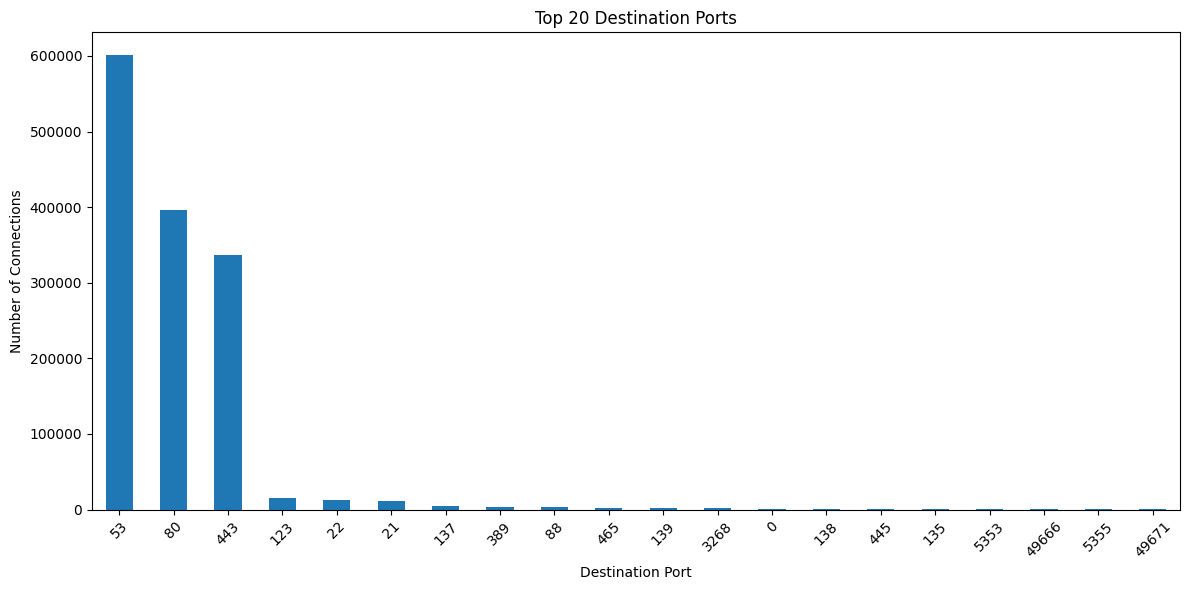

In [33]:
port_counts = train_df["Destination Port"].value_counts().head(20)

plt.figure(figsize=(12, 6))
port_counts.plot(kind="bar")

plt.xlabel("Destination Port")
plt.ylabel("Number of Connections")
plt.title("Top 20 Destination Ports")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
print(f"There are a total of {len(train_df['Destination Port'].unique())} unique values in the feature Deastination port")

There are a total of 47258 unique values in the feature Deastination port


In [35]:
# here are the top 20 Destination port values
display(pd.DataFrame(port_counts))

,count
Destination Port,
53,601139
80,396371
443,337031
123,14597
22,12299
21,11049
137,4908
389,3662
88,3368


In [36]:
port_counts = train_df["Destination Port"].value_counts()

top_10_percentage = (
    port_counts.head(5).sum()
    / len(train_df)
    * 100
)

top_20_percentage = (
    port_counts.head(20).sum()
    / len(train_df)
    * 100
)

print(f"Top 5 ports cover {top_10_percentage:.2f}% of flows")
print(f"Top 20 ports cover {top_20_percentage:.2f}% of flows")

Top 5 ports cover 81.78% of flows
Top 20 ports cover 83.75% of flows


### Handling the Destination Port Feature

The `Destination Port` feature represents the destination port number associated with a network flow. Although port numbers are identifiers rather than continuous measurements, they are represented as integers in network traffic data.

During exploratory data analysis, we found that this feature contains 47,258 unique values, with most network flows concentrated in a small number of frequently used ports. We will retain the feature in its numerical form for the initial Isolation Forest baseline rather than converting every unique port into a separate categorical feature.

This decision preserves the original port information without introducing a large number of additional features through one-hot encoding. However, because port numbers are identifiers and their numerical distances do not necessarily represent meaningful similarities, we will evaluate alternative representations in future experiments if needed.


Before creating any new features, let's establish exactly which features we're keeping.

In [37]:
pd.set_option("display.max_rows", None)

feature_summary = pd.DataFrame({
    "dtype": train_df.dtypes,
    "unique_values": train_df.nunique(),
    "missing_values": train_df.isna().sum(),
    "zero_fraction": (train_df == 0).sum() / train_df.shape[0]
})

display(feature_summary)

,dtype,unique_values,missing_values,zero_fraction
Destination Port,int64,47258,0,5.78e-04
Flow Duration,int64,689419,0,0.00e+00
Total Fwd Packets,int64,897,0,0.00e+00
Total Backward Packets,int64,1131,0,1.62e-01
Total Length of Fwd Packets,int64,14458,0,1.73e-01
Total Length of Bwd Packets,int64,47023,0,2.76e-01
Fwd Packet Length Max,int64,4728,0,1.73e-01
Fwd Packet Length Min,int64,315,0,5.18e-01
Fwd Packet Length Mean,float64,75028,0,1.73e-01
Fwd Packet Length Std,float64,171493,0,6.16e-01


In [38]:
zero_dominated = feature_summary[
    feature_summary["zero_fraction"] >= 0.95
]

display(zero_dominated)

,dtype,unique_values,missing_values,zero_fraction
RST Flag Count,int64,2,0,1.0
ECE Flag Count,int64,2,0,1.0


In [39]:
for feature in ["RST Flag Count", "ECE Flag Count"]:
    print(f"\n{feature}")
    print(train_df[feature].value_counts())


RST Flag Count
RST Flag Count
0    1664281
1        451
Name: count, dtype: int64

ECE Flag Count
ECE Flag Count
0    1664278
1        454
Name: count, dtype: int64


We will retain these feature because non-zero values may indicate attack-behaviour 

**Let's check for exactly identical columns**

In [40]:
# Check for exact duplicate columns
column_hashes = train_df.apply(
    lambda col: pd.util.hash_pandas_object(col, index=False).sum()
)

duplicate_features = column_hashes[
    column_hashes.duplicated(keep="first")
].index

print(duplicate_features.tolist())

['SYN Flag Count', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets']


**We will investigate further to get the exact feature names to confirm the duplicacy of feature values:**

In [41]:
for col in train_df.columns:
    duplicate_of = [c for c in train_df.columns\
    if c != col and train_df[c].equals(train_df[col])]

    if len(duplicate_of) > 0:
        print(f"{col} == {duplicate_of}")

Total Fwd Packets == ['Subflow Fwd Packets']
Total Backward Packets == ['Subflow Bwd Packets']
Total Length of Fwd Packets == ['Subflow Fwd Bytes']
Fwd PSH Flags == ['SYN Flag Count']
Fwd Header Length == ['Fwd Header Length.1']
SYN Flag Count == ['Fwd PSH Flags']
Fwd Header Length.1 == ['Fwd Header Length']
Subflow Fwd Packets == ['Total Fwd Packets']
Subflow Fwd Bytes == ['Total Length of Fwd Packets']
Subflow Bwd Packets == ['Total Backward Packets']


### Removal of Duplicate Features

During feature-quality analysis, we identified several features that contained exactly the same values as other features in the training dataset. These duplicate features provide redundant information because they do not add any new predictive information to the model.

Keeping redundant features can unnecessarily increase the dimensionality of the dataset, make the model more complex, and make feature interpretation more difficult. Therefore, when two features contain identical information, we retain one representative feature and remove the duplicate.

The following duplicate features will be removed:

* **`Subflow Fwd Packets`** — duplicate of `Total Fwd Packets`
* **`Subflow Bwd Packets`** — duplicate of `Total Backward Packets`
* **`Subflow Fwd Bytes`** — duplicate of `Total Length of Fwd Packets`
* **`Fwd PSH Flags`** - duplicate of `SYN Flag Count`
* **`Fwd Header Length.1`** - duplicate of `Fwd Header Length`

The representative features were retained because they have clearer and more intuitive names for describing the corresponding network traffic measurements.

**Note:** `Fwd PSH Flags` and `SYN Flag Count` represent different TCP behaviors, but their values are identical in this dataset. Therefore, removing one eliminates numerical redundancy while retaining the same information available to the model.

In [42]:
# Redundant columns 
redundant_features = [
    "Subflow Fwd Packets",
    "Subflow Bwd Packets",
    "Subflow Fwd Bytes",
    "Fwd PSH Flags",
    "Fwd Header Length.1"
]

In [43]:
train_df = train_df.drop(columns=redundant_features + ["Label"])

In [44]:
len((train_df.columns))

64

In [45]:
train_df.columns

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length',
       'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length',
       'Max Packet Length', 'Packet Length Mean', 'Packet Length Std',
       'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count',
       'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count

In [46]:
print("Shape:", train_df.shape)
print("Target distribution:")
print(train_df["target"].value_counts())
print("Missing values:", train_df.isna().sum().sum())

Shape: (1664732, 64)
Target distribution:
target
0    1399351
1     265381
Name: count, dtype: int64
Missing values: 0


In [47]:
display(pd.DataFrame(train_df["target"].value_counts(normalize=True)))

,proportion
target,
0,0.84
1,0.16


### Next we will check the correlation between features:

In [48]:
# Exclude the target from the features
X_train = train_df.drop(columns=["target"])

# Calculate feature correlations
corr_matrix = X_train.corr().abs()

# Get the upper triangle to avoid duplicate pairs
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find highly correlated feature pairs
high_corr = (
    upper_triangle
    .stack()
    .loc[lambda x: x >= 0.95]
    .sort_values(ascending=False)
)

print(high_corr)

Bwd Packet Length Mean       Avg Bwd Segment Size           1.00
Fwd Packet Length Mean       Avg Fwd Segment Size           1.00
Total Length of Bwd Packets  Subflow Bwd Bytes              1.00
Flow Duration                Fwd IAT Total                  1.00
Flow IAT Max                 Fwd IAT Max                    1.00
Packet Length Mean           Average Packet Size            1.00
RST Flag Count               ECE Flag Count                 1.00
Total Backward Packets       Bwd Header Length              1.00
Idle Mean                    Idle Min                       1.00
                             Idle Max                       1.00
Total Fwd Packets            Total Backward Packets         0.99
Total Backward Packets       Total Length of Bwd Packets    0.99
                             Subflow Bwd Bytes              0.99
Flow Packets/s               Fwd Packets/s                  0.99
Total Fwd Packets            Fwd Header Length              0.99
Flow IAT Max             

# Handling Highly Correlated Features for Isolation Forest

At this stage, we will retain all features, including highly correlated features, in the training dataset. Although highly correlated features may contain redundant information, we will not remove them solely based on correlation analysis.

Isolation Forest is a tree-based, unsupervised anomaly detection algorithm that isolates observations through random feature selection and random split points. Unlike linear models, it does not rely on estimating regression coefficients, so multicollinearity is not a direct concern.

However, highly correlated features can still influence anomaly detection. When multiple features carry similar information, they may receive repeated opportunities to influence the isolation process, potentially affecting anomaly scores and feature selection.

Therefore, we will initially retain all features and establish a baseline Isolation Forest model. We will then evaluate its performance and investigate whether removing redundant features improves anomaly detection, particularly its ability to identify minority attack traffic.

Feature removal will be based on empirical evaluation rather than correlation alone. Any feature selection and preprocessing decisions will be made using the training and validation datasets. The test dataset will remain untouched until the final evaluation to avoid data leakage and provide an unbiased assessment of the model's generalization performance.

### Applying Training Data Transformations to Validation and Test Sets

The transformations and preprocessing steps established using the training dataset will now be applied consistently to the validation and test datasets. Both datasets will be prepared using the same feature selection, data cleaning, and preprocessing procedures applied to the training data to ensure consistency across all three datasets.

Any preprocessing parameters learned from the training data (such as imputation values, scaling parameters, or encoding mappings) will be reused rather than refitted on the validation or test data. This approach prevents data leakage and ensures a fair evaluation of model performance on unseen data.

The summary of pre-processing we carried out:


## Data Cleaning and Feature Selection

Before training the Isolation Forest model, we will clean the CICIDS test and validation datasets using the same cleaning rules will be applied to the training set.

1. **Remove duplicate columns:** Drop `Fwd Header Length.1`, which duplicates `Fwd Header Length`.

2. **Handle negative values:** Remove observations containing negative values in any of the following features: `Flow IAT Min`, `Flow Duration`, `Flow Packets/s`, `Flow IAT Mean`, `Flow IAT Max`, `Fwd Header Length`, `min_seg_size_forward`, `Flow Bytes/s`, `Bwd Header Length`, and `Fwd IAT Min`.

4. **Handle infinite values:** Remove observations containing positive or negative infinity in any model feature. Infinite values were identified in `Flow Bytes/s` and `Flow Packets/s` in the training set.

5. **Remove zero-only features:** Drop features containing only zeros because they provide no variation for the model to learn from.

   We identified features ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'] in the trainset and dropped them. We will apply the same rules for the test and validation sets.

7. **Remove redundant features:** Drop redundant columns identified during exploratory data analysis: `Subflow Fwd Packets`, `Subflow Bwd Packets`, `Subflow Fwd Bytes`, and `Fwd PSH Flags`.

8. **Remove the original label column:** Drop `Label` from the model inputs. Retain `target` separately for model evaluation and exclude it from the Isolation Forest input features.

These preprocessing decisions are established using the training data and exploratory analysis. The resulting feature set and cleaning rules will remain consistent across all data splits to avoid data leakage.

In [49]:
negative_value_features

['Flow IAT Min',
 'Flow Duration',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Max',
 'Fwd Header Length',
 'min_seg_size_forward',
 'Flow Bytes/s',
 'Bwd Header Length',
 'Fwd IAT Min']

In [50]:
zero_only_features

Index(['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count',
       'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate',
       'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'],
      dtype='object')

In [51]:
list(zero_only_features) + (redundant_features) + ["Label"]

['Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'CWE Flag Count',
 'Fwd Avg Bytes/Bulk',
 'Fwd Avg Packets/Bulk',
 'Fwd Avg Bulk Rate',
 'Bwd Avg Bytes/Bulk',
 'Bwd Avg Packets/Bulk',
 'Bwd Avg Bulk Rate',
 'Subflow Fwd Packets',
 'Subflow Bwd Packets',
 'Subflow Fwd Bytes',
 'Fwd PSH Flags',
 'Fwd Header Length.1',
 'Label']

In [52]:
columns_to_drop = list(zero_only_features) + redundant_features + ["Label"]

# Clean validation and test sets
datasets = {
    "validation": val_df,
    "test": test_df
}

for name, df in datasets.items():
    rows_before = len(df)

    # 1. Remove rows with negative values in specified features
    negative_cols = [
        col for col in negative_value_features
        if col in df.columns
    ]

    negative_mask = df[negative_cols].lt(0).any(axis=1)
    df = df.loc[~negative_mask].copy()
    negative_removed = int(negative_mask.sum())

    # 2. Remove rows containing positive or negative infinity
    feature_cols = [
        col for col in df.columns
        if col not in ["target", "Label"]
    ]

    infinite_mask = np.isinf(df[feature_cols]).any(axis=1)
    df = df.loc[~infinite_mask].copy()
    infinite_removed = int(infinite_mask.sum())

    # 3. Drop the same columns identified using training data
    existing_columns = [
        col for col in columns_to_drop
        if col in df.columns
    ]
    df.drop(columns=existing_columns, inplace=True)

    datasets[name] = df

    print(f"\n{name.capitalize()} set")
    print(f"Rows before cleaning: {rows_before}")
    print(f"Rows removed for negative values: {negative_removed}")
    print(f"Rows removed for infinite values: {infinite_removed}")
    print(f"Rows after cleaning: {len(df)}")
    print(f"Columns dropped: {len(existing_columns)}")
    print(f"Final shape: {df.shape}")

# Update the original variables
val_df = datasets["validation"]
test_df = datasets["test"]


Validation set
Rows before cleaning: 458968
Rows removed for negative values: 616
Rows removed for infinite values: 342
Rows after cleaning: 458010
Columns dropped: 16
Final shape: (458010, 64)

Test set
Rows before cleaning: 703245
Rows removed for negative values: 509
Rows removed for infinite values: 527
Rows after cleaning: 702209
Columns dropped: 16
Final shape: (702209, 64)


In [53]:
print(f"Final shape for the train_data {train_df.shape}")

Final shape for the train_data (1664732, 64)


Now we will start with the modeling process:

In [54]:
# Getting the train, val and test sets ready
X_train = train_df.drop(columns=['target'])
y_train = train_df['target'].copy()

X_val = val_df.drop(columns=["target"])
y_val = val_df["target"].copy()

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"].copy()

# Check target encoding and class distribution
print("Training data distribution")
print(y_train.value_counts(dropna=False))

print("Validation data distribution")
print(y_val.value_counts(dropna=False))

print("Test data distribution")
print(y_test.value_counts(dropna=False))

# Check dataset dimensions
print("\nDataset shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

# verify all the sets have the same features
print(f"Columns in train set and validation set are identical: {X_train.columns.equals(X_val.columns)}")
print(f"Columns in train set and test set are identical: {X_train.columns.equals(X_test.columns)}")

# Check for missing and infinite values
print("\nMissing values:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nInfinite values:")
print(f"Train : {np.isinf(X_train).to_numpy().sum()}")
print(f"Validation : {np.isinf(X_val).to_numpy().sum()}")
print(f"Test : {np.isinf(X_test).to_numpy().sum()}")

Training data distribution
target
0    1399351
1     265381
Name: count, dtype: int64
Validation data distribution
target
0    455795
1      2215
Name: count, dtype: int64
Test data distribution
target
0    413443
1    288766
Name: count, dtype: int64

Dataset shapes:
X_train: (1664732, 63)
X_val: (458010, 63)
X_test: (702209, 63)
Columns in train set and validation set are identical: True
Columns in train set and test set are identical: True

Missing values:
Train: 0
Validation: 0
Test: 0

Infinite values:
Train : 0
Validation : 0
Test : 0


In [55]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
classification_report, 
average_precision_score,
confusion_matrix,
precision_recall_curve
)

In [56]:
# Select benign traffic for unsupervised training
X_train_benign = X_train.loc[y_train == 0]
print("Benign training samples:", len(X_train_benign))

# Initialize Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination='auto',
    random_state=42,
    n_jobs=-1
)

iso_forest.fit(X_train_benign)

print("Isolation Forest training complete.")

Benign training samples: 1399351
Isolation Forest training complete.


In [57]:
#isolation forest's validation prediction
# inlier = 1 (normal)
# outlier = -1 (anomaly)
val_predictions_raw = iso_forest.predict(X_val)

# Convert to our target convention:
#  0 = benign
#  1 = attack
y_val_pred = (val_predictions_raw == -1).astype(int)

# confusion matrix
print("Confusion matrix")
print(confusion_matrix(y_val, y_val_pred))

# classification report
print("\nClassification Report:")
print(classification_report(
    y_val, 
    y_val_pred,
labels=[0, 1],
target_names=["Benign", "Attack"],
zero_division=0
))

Confusion matrix
[[426943  28852]
 [  2095    120]]

Classification Report:
              precision    recall  f1-score   support

      Benign       1.00      0.94      0.97    455795
      Attack       0.00      0.05      0.01      2215

    accuracy                           0.93    458010
   macro avg       0.50      0.50      0.49    458010
weighted avg       0.99      0.93      0.96    458010



Our metrics for attack class on the validatrion are very poor.

### **First diagnostic: inspect anomaly scores and thresholds**
- Before retraining, let's determine whether the model can rank attacks above benign traffic but is using a poor default threshold, or whether the scores themselves have little ability to distinguish the classes.

- What we're looking for
    - Score distributions: Are attack scores generally higher than benign scores?
    - Best achievable validation F1: Does adjusting the threshold meaningfully improve detection?
    - Precision versus recall: Can we catch more attacks without flagging an overwhelming number of benign records?

In [58]:
# Higher scores indicate more anomalous observations
val_scores = -iso_forest.score_samples(X_val)

print("Average Precision:",
      average_precision_score(y_val, val_scores))

display(
    pd.DataFrame({
        "Label": y_val,
        "Anomaly_Score": val_scores
    })
    .groupby("Label")["Anomaly_Score"]
    .describe()
    .round(5)
)

# Find the best F1 threshold on validation data
precision, recall, thresholds = precision_recall_curve(
    y_val, val_scores
)

f1 = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = f1.argmax()

print(f"\nBest validation F1: {f1[best_idx]:.5f}")
print(f"Precision:          {precision[best_idx]:.5f}")
print(f"Recall:             {recall[best_idx]:.5f}")
print(f"Threshold:          {thresholds[best_idx]:.5f}")

Average Precision: 0.011335466336013855


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
0,455795.0,0.37,0.06,0.32,0.33,0.35,0.38,0.76
1,2215.0,0.39,0.05,0.33,0.38,0.38,0.38,0.73



Best validation F1: 0.03484
Precision:          0.01776
Recall:             0.91332
Threshold:          0.38274


Isolation Forest is giving attack traffic somewhat higher anomaly scores, but the separation is not strong enough for reliable detection.
Now we need to decide whether we can improve that separation or whether we need a different modeling approach. We'll do this systematically, without jumping straight into random hyperparameter tuning.

In [59]:
# Inspect unique score values and score concentration
print("Unique validation scores:", np.unique(val_scores).size)

print("\nMost frequent rounded anomaly scores:")
display(
    pd.Series(val_scores)
    .round(6)
    .value_counts()
    .head(15)
)

print("\nScore quantiles by class:")
display(
    pd.DataFrame({
        "Label": np.asarray(y_val),
        "Score": val_scores
    })
    .groupby("Label")["Score"]
    .quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .unstack()
    .round(6)
)

Unique validation scores: 111831

Most frequent rounded anomaly scores:


0.34    8238
0.34    5357
0.36    4106
0.34    3520
0.33    3214
0.33    3147
0.34    2730
0.36    2512
0.36    2292
0.33    2202
0.34    1650
0.36    1597
0.35    1561
0.36    1501
0.35    1460
Name: count, dtype: int64


Score quantiles by class:


,0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99
Label,,,,,,,,,
0,0.32,0.32,0.32,0.33,0.35,0.38,0.45,0.53,0.62
1,0.34,0.34,0.38,0.38,0.38,0.38,0.38,0.57,0.63


The unusual pattern is that the 10th through 90th percentiles of attack scores are tightly packed around 0.383. Meanwhile, benign scores vary much more widely.
That suggests two things:
- Many attacks receive almost identical scores, so the model may have limited ability to rank those attacks against one another.
- Some benign records receive scores higher than most attacks, which creates false positives.
There are still 111,831 distinct validation scores, so the model is not producing only a handful of scores. The concentration around 0.383 is a pattern worth investigating, not proof of a model defect.


- The training data contains about 15.9% attacks, while validation contains only 0.48% attacks. Since we used a temporal split, the attack rate changed dramatically between periods.That might be a genuine change in traffic, a change in attack types, or a dataset collection issue. Before adjusting the model, we should inspect the class distribution across the original time periods.

### Revising the Validation and Test Split

We evaluated our baseline Isolation Forest model and observed poor attack detection performance. The validation set contains only approximately **0.48% attack observations**, making it highly imbalanced and providing limited attack examples for reliable model evaluation and threshold tuning.

To improve validation, we will revise the chronological data split while keeping the training data unchanged:

- **Training:** Monday, Tuesday, and Wednesday traffic.
- **Validation:** Thursday morning, Thursday afternoon, and Friday morning traffic.
- **Test:** Friday afternoon DDoS and PortScan traffic.

This revision adds more attack observations to validation while preserving the chronological order of the source files and keeping the test data separate from model tuning.

After updating the ingestion script, we will regenerate the processed datasets and rerun the Jupyter notebook from the beginning. All preprocessing transformations, Isolation Forest training, validation evaluation, and threshold tuning will be repeated using the revised split. The test set will be reserved for final evaluation after model decisions are finalized.

In [60]:
rev_validation_dir = data_dir/"validation_rev"
rev_test_dir = data_dir/"test_rev"

rev_validation_files = list(rev_validation_dir.glob("*.csv"))
rev_test_files = list(rev_test_dir.glob("*.csv"))


rev_val_df = combine_files(rev_validation_files)
rev_test_df = combine_files(rev_test_files)

In [61]:
# Clean validation and test sets
datasets = {
    "validation": rev_val_df,
    "test": rev_test_df
}

for name, df in datasets.items():
    rows_before = len(df)

    # 1. Remove rows with negative values in specified features
    negative_cols = [
        col for col in negative_value_features
        if col in df.columns
    ]

    negative_mask = df[negative_cols].lt(0).any(axis=1)
    df = df.loc[~negative_mask].copy()
    negative_removed = int(negative_mask.sum())

    # 2. Remove rows containing positive or negative infinity
    feature_cols = [
        col for col in df.columns
        if col not in ["target", "Label"]
    ]

    infinite_mask = np.isinf(df[feature_cols]).any(axis=1)
    df = df.loc[~infinite_mask].copy()
    infinite_removed = int(infinite_mask.sum())

    # 3. Drop the same columns identified using training data
    existing_columns = [
        col for col in columns_to_drop
        if col in df.columns
    ]
    df.drop(columns=existing_columns, inplace=True)

    datasets[name] = df

    print(f"\n{name.capitalize()} set")
    print(f"Rows before cleaning: {rows_before}")
    print(f"Rows removed for negative values: {negative_removed}")
    print(f"Rows removed for infinite values: {infinite_removed}")
    print(f"Rows after cleaning: {len(df)}")
    print(f"Columns dropped: {len(existing_columns)}")
    print(f"Final shape: {df.shape}")

# Update the original variables
val_df = datasets["validation"]
test_df = datasets["test"]


Validation set
Rows before cleaning: 650001
Rows removed for negative values: 841
Rows removed for infinite values: 464
Rows after cleaning: 648696
Columns dropped: 16
Final shape: (648696, 64)

Test set
Rows before cleaning: 512212
Rows removed for negative values: 284
Rows removed for infinite values: 405
Rows after cleaning: 511523
Columns dropped: 16
Final shape: (511523, 64)


In [62]:
test_df.to_csv(data_dir/"test_sample.csv", index=False)

In [63]:
X_val = val_df.drop(columns=["target"])
y_val = val_df["target"].copy()

X_test = test_df.drop(columns=["target"])
y_test = test_df["target"].copy()


print("Validation data distribution")
print(y_val.value_counts(dropna=False))

print("Test data distribution")
print(y_test.value_counts(dropna=False))

# Check dataset dimensions
print("\nDataset shapes:")

print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

# verify all the sets have same features
print(f"Columns in train set and validation set are identical: {X_train.columns.equals(X_val.columns)}")
print(f"Columns in train set and test set are identical: {X_train.columns.equals(X_test.columns)}")


# Check for missing and infinite values
print("\nMissing values:")
print("Validation:", X_val.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nInfinite values:")
print(f"Validation : {np.isinf(X_val).to_numpy().sum()}")
print(f"Test : {np.isinf(X_test).to_numpy().sum()}")


Validation data distribution
target
0    644525
1      4171
Name: count, dtype: int64
Test data distribution
target
1    286810
0    224713
Name: count, dtype: int64

Dataset shapes:
X_val: (648696, 63)
X_test: (511523, 63)
Columns in train set and validation set are identical: True
Columns in train set and test set are identical: True

Missing values:
Validation: 0
Test: 0

Infinite values:
Validation : 0
Test : 0


In [64]:
#isolation forest's validation prediction
# inlier = 1 (normal)
# outlier = -1 (anomaly)
val_predictions_raw = iso_forest.predict(X_val)

# Convert to our target convention:
#  0 = benign
#  1 = attack
y_val_pred = (val_predictions_raw == -1).astype(int)

# confusion matrix
print("Confusion matrix")
print(confusion_matrix(y_val, y_val_pred))

# classification report
print("\nClassification Report:")
print(classification_report(
    y_val, 
    y_val_pred,
labels=[0, 1],
target_names=["Benign", "Attack"],
zero_division=0
))

# Higher anomaly scores indicate more anomalous observations
val_anomaly_scores = -iso_forest.score_samples(X_val)



print(
    "\nValidation Average Precision:",
    average_precision_score(y_val, val_anomaly_scores)
)

Confusion matrix
[[601114  43411]
 [  4007    164]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      0.93      0.96    644525
      Attack       0.00      0.04      0.01      4171

    accuracy                           0.93    648696
   macro avg       0.50      0.49      0.48    648696
weighted avg       0.99      0.93      0.96    648696


Validation Average Precision: 0.010321223491674556


In [65]:
# Higher scores indicate more anomalous observations
val_scores = -iso_forest.score_samples(X_val)

print("Average Precision:",
      average_precision_score(y_val, val_scores))

display(
    pd.DataFrame({
        "Label": y_val,
        "Anomaly_Score": val_scores
    })
    .groupby("Label")["Anomaly_Score"]
    .describe()
    .round(5)
)

# Find the best F1 threshold on validation data
precision, recall, thresholds = precision_recall_curve(
    y_val, val_scores
)

f1 = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = f1.argmax()

print(f"\nBest validation F1: {f1[best_idx]:.5f}")
print(f"Precision:          {precision[best_idx]:.5f}")
print(f"Recall:             {recall[best_idx]:.5f}")
print(f"Threshold:          {thresholds[best_idx]:.5f}")

Average Precision: 0.010321223491674556


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
0,644525.0,0.37,0.07,0.32,0.33,0.35,0.38,0.76
1,4171.0,0.38,0.05,0.33,0.35,0.38,0.38,0.73



Best validation F1: 0.02576
Precision:          0.01314
Recall:             0.63702
Threshold:          0.37014


#### Next Experiment: Supervised Random Forest

Why are we trying Random Forest?

Our baseline Isolation Forest model showed poor attack detection performance on the revised validation dataset. Its Average Precision (AP) was 0.01032, and its best F1-score was only 0.02576, even after tuning the anomaly-score threshold.

The score distributions for benign and attack observations overlap substantially, indicating that Isolation Forest struggles to distinguish malicious traffic from normal traffic based on anomaly scores alone.

Isolation Forest is an unsupervised anomaly detection algorithm. It identifies observations that are unusual relative to the overall data distribution, but unusual network traffic is not necessarily malicious traffic. Conversely, some attacks may resemble normal traffic and therefore receive low anomaly scores.

Why Random Forest?

We will now evaluate a supervised classification approach using Random Forest. Unlike Isolation Forest, Random Forest learns from the labeled training observations to identify patterns associated with benign and attack traffic.

We will use class_weight="balanced" to account for the class imbalance in the training data by assigning greater weight to the minority attack class.

Experimental approach

Train Random Forest using the existing training dataset and its binary target labels.

Evaluate predictions on the revised validation dataset.

Measure performance using the confusion matrix, precision, recall, F1-score, and Average Precision.

Tune the classification threshold using validation data to investigate the trade-off between detecting attacks and minimizing false positives.

Compare the results with the Isolation Forest baseline.

The test dataset will remain untouched during model selection and threshold tuning. Once the model and threshold are finalized, we will use the test dataset for the final evaluation.

Objective

The objective is to determine whether a supervised model can distinguish attack traffic from benign traffic more effectively than our unsupervised baseline. This comparison will help us assess whether learning from labeled attack examples improves detection performance on the validation data.

In [66]:
from sklearn.ensemble import RandomForestClassifier

In [67]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [68]:
# Predict attack probabilities
val_probs = rf.predict_proba(X_val)[:, 1]

# Default threshold = 0.5
y_val_pred = (val_probs >= 0.5).astype(int)


print("Confusion matrix")
print(confusion_matrix(y_val, y_val_pred))

Confusion matrix
[[644361    164]
 [  4032    139]]


In [69]:
print("Classification report")


print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


print("Validation Average Precision Score")
print(average_precision_score(y_val, val_probs))

Classification report
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00    644525
      Attack       0.46      0.03      0.06      4171

    accuracy                           0.99    648696
   macro avg       0.73      0.52      0.53    648696
weighted avg       0.99      0.99      0.99    648696

Validation Average Precision Score
0.38220161853787005


In [70]:
precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

print(f"Best validation F1: {f1_scores[best_idx]:.5f}")
print(f"Precision: {precision[best_idx]:.5f}")
print(f"Recall: {recall[best_idx]:.5f}")
print(f"Threshold: {best_threshold:.5f}")

Best validation F1: 0.59690
Precision: 0.87610
Recall: 0.45265
Threshold: 0.29000


Model Comparison: Isolation Forest vs. Random Forest

After evaluating the Isolation Forest model, we trained a supervised Random Forest classifier to determine whether learning from labeled benign and attack traffic could improve detection performance.

- Improved overall detection quality: Random Forest achieved an Average Precision of 0.38220 (38.22%), compared with 0.01032 (1.03%) for Isolation Forest. This is approximately a 37-fold increase in Average Precision, indicating substantially better ranking of attack traffic above benign traffic.

- Substantial improvement in attack precision: At its tuned threshold of 0.29, Random Forest achieved an attack precision of 87.61%, compared with only 1.314% for Isolation Forest at its tuned threshold. Thus, the proportion of predicted attacks that were actually attacks increased by approximately 86.30 percentage points. This means Random Forest produces far fewer false alarms relative to its attack predictions.

- Trade-off in attack recall: Isolation Forest achieved 63.70% attack recall at its tuned threshold, whereas Random Forest achieved 45.27%. Therefore, Random Forest missed a larger proportion of actual attacks at these selected operating points. Its improvement is not in detecting a greater proportion of all attacks at these thresholds, but in making substantially more reliable attack predictions.

- Improved F1-score: Random Forest achieved an attack F1-score of 0.59690, compared with 0.02576 for Isolation Forest. This demonstrates a substantial improvement in the balance between attack precision and recall.

**Conclusion**

Random Forest substantially outperformed Isolation Forest on the revised validation dataset in Average Precision, attack precision, and attack F1-score. Isolation Forest identifies unusual observations without using attack labels during training, but unusual benign traffic can also receive high anomaly scores. Random Forest, in contrast, learns from labeled examples and can identify patterns that distinguish benign traffic from attacks.

For this project, Random Forest is the stronger candidate for attack detection because its predictions are considerably more precise and its precision–recall performance is substantially better. However, the lower attack recall at the selected threshold means that some attacks remain undetected. The threshold should therefore be selected according to the operational trade-off between false alarms and missed attacks.

The next step is to evaluate the finalized Random Forest model on the held-out test set using the selected validation threshold of 0.29. The test set must not be used to tune the model or threshold.

In [71]:
# test set prediction probability
y_test_prob = rf.predict_proba(X_test)[:, 1]

# test set predictions
y_test_pred = (y_test_prob >= 0.29).astype(int)

# Confusion matrix for test set
print("Confusion matrix for the test set:-")
print(confusion_matrix(y_test, y_test_pred))

# classification report for the test set
print("\nClassification report for the test data:-")
print(classification_report(y_test, 
                            y_test_pred, 
                            target_names=["Benign", "Attack"],
                            zero_division=0
                           ))


Confusion matrix for the test set:-
[[224559    154]
 [205049  81761]]

Classification report for the test data:-
              precision    recall  f1-score   support

      Benign       0.52      1.00      0.69    224713
      Attack       1.00      0.29      0.44    286810

    accuracy                           0.60    511523
   macro avg       0.76      0.64      0.56    511523
weighted avg       0.79      0.60      0.55    511523



## Random Forest: Test Set Evaluation

After selecting the Random Forest classification threshold of **0.29** using the validation set, we evaluated the model on the held-out test set containing Friday-afternoon DDoS and PortScan traffic.

### 1. Test Set Results

The confusion matrix is:

\[
\begin{bmatrix}
224559 & 154\\
205049 & 81761
\end{bmatrix}
\]

Using benign traffic as class 0 and attack traffic as class 1:

- **True Negatives (TN):** 224,559 benign records correctly classified as benign.
- **False Positives (FP):** 154 benign records incorrectly classified as attacks.
- **False Negatives (FN):** 205,049 attack records incorrectly classified as benign.
- **True Positives (TP):** 81,761 attack records correctly classified as attacks.

### 2. Interpretation of the Classification Report

**Attack precision: 1.00 (approximately 99.81%)**

Almost every record predicted as an attack was actually an attack. Only 154 benign records were incorrectly flagged as attacks out of 81,915 total attack predictions.

**Attack recall: 0.29 (approximately 28.51%)**

The model detected 81,761 of the 286,810 actual attack records. However, it missed 205,049 attacks, corresponding to approximately 71.49% of all attacks in the test set.

**Attack F1-score: 0.44 (approximately 44.38%)**

The F1-score reflects the trade-off between very high attack precision and relatively low attack recall.

**Accuracy: 0.60 (approximately 59.92%)**

The model correctly classified 306,320 of the 511,523 test records. Accuracy alone does not adequately describe the model's performance because it does not distinguish between false alarms and missed attacks.

### 3. Comparison with Validation Performance

At the selected threshold of 0.29, Random Forest achieved the following validation metrics:

| Metric | Validation | Test |
|---|---:|---:|
| Attack precision | 87.61% | 99.81% |
| Attack recall | 45.27% | 28.51% |
| Attack F1-score | 59.69% | 44.38% |

Attack precision increased on the test set, while attack recall and F1-score decreased. This indicates that the model's ability to identify a large proportion of attacks did not generalize as well to the held-out test traffic.

The test set contains Friday-afternoon DDoS and PortScan attacks, which may have different traffic patterns from those in the training and validation sets. This distribution difference is a plausible explanation for the lower recall and should be investigated further.

### 4. Conclusion and Next Steps

The Random Forest model is highly precise when it predicts an attack, but its current operating threshold misses a substantial proportion of actual attacks. In a cybersecurity application, these missed attacks are important because they represent potentially malicious traffic that passes undetected.

The next step is to investigate the validation–test performance gap and evaluate whether a different threshold can improve attack recall while maintaining an acceptable false-positive rate. Any threshold changes must be based on the validation set, not the test set. The held-out test results should remain the final unbiased evaluation of the selected model.

In [72]:
 # Get predicted probabilities for the attack class (Label = 1)
val_probs = rf.predict_proba(X_val)[:, 1]
test_probs = rf.predict_proba(X_test)[:, 1]

# Create a summary of probability distributions by actual class
val_summary = pd.DataFrame({
    "Actual_Label": y_val.to_numpy() if hasattr(y_val, "to_numpy") else y_val,
    "Attack_Probability": val_probs
})

test_summary = pd.DataFrame({
    "Actual_Label": y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test,
    "Attack_Probability": test_probs
})

print("Validation probability summary:")
print(val_summary.groupby("Actual_Label")["Attack_Probability"].describe().round(4))


print("\nTest probability summary:")
print(test_summary.groupby("Actual_Label")["Attack_Probability"].describe().round(4))

Validation probability summary:
                 count      mean   std  min  25%   50%   75%   max
Actual_Label                                                      
0             644525.0  3.10e-03  0.02  0.0  0.0  0.00  0.00  1.00
1               4171.0  2.12e-01  0.23  0.0  0.0  0.03  0.45  0.96

Test probability summary:
                 count      mean   std  min       25%   50%   75%  max
Actual_Label                                                          
0             224713.0  2.70e-03  0.02  0.0  0.00e+00  0.00  0.00  1.0
1             286810.0  1.74e-01  0.24  0.0  5.00e-03  0.03  0.49  1.0


### Experiment: Destination Port Feature Engineering
The Destination Port feature is currently treated as a numerical variable. I would like to experiment with feature engineering by grouping destination port numbers into three categories:
1. Well-Known Ports: 0–1023
2. Registered Ports: 1024–49151
3. Dynamic/Private Ports: 49152–65535
I will create a new categorical feature based on these groups and train a Random Forest model using this newly engineered feature to evaluate its impact on model performance, particularly its ability to detect attacks.

I will compare the results with the baseline model to determine whether grouping destination ports provides any meaningful improvement in attack detection performance.

In [73]:
def inspect_destination_ports(X, y, split_name):
    df = pd.DataFrame({
        "Destination Port": X["Destination Port"].to_numpy(),
        "target": np.asarray(y)
    })

    # Ensure the port column is numeric
    df["Destination Port"] = pd.to_numeric(
        df["Destination Port"], errors="coerce"
    )
    df = df.dropna(subset=["Destination Port"])

    print(f"\n{'=' * 20} {split_name} {'=' * 20}")
    print(f"Total records: {len(df):,}")

    # Most frequent destination ports and their attack rates
    port_summary = (
        df.groupby("Destination Port")
        .agg(
            total_records=("target", "size"),
            attacks=("target", "sum"),
            attack_rate=("target", "mean")
        )
        .sort_values("total_records", ascending=False)
    )

    print("\nTop 15 destination ports:")
    print(port_summary.head(15).round(4))

    # Broad port ranges
    df["port_range"] = pd.cut(
        df["Destination Port"],
        bins=[-1, 1023, 49151, 65535],
        labels=[
            "Well-known (0–1023)",
            "Registered (1024–49151)",
            "Dynamic/private (49152–65535)"
        ]
    )

    range_summary = (
        df.groupby("port_range", observed=False)
        .agg(
            total_records=("target", "size"),
            attacks=("target", "sum"),
            attack_rate=("target", "mean")
        )
    )

    print("\nPort range summary:")
    print(range_summary.round(4))


inspect_destination_ports(X_train, y_train, "Training")
inspect_destination_ports(X_val, y_val, "Validation")
inspect_destination_ports(X_test, y_test, "Test")



==================== Training ====================
Total records: 1,664,732

Top 15 destination ports:
                  total_records  attacks  attack_rate
Destination Port                                     
53                       601139        0         0.00
80                       396371   251549         0.63
443                      337031        0         0.00
123                       14597        0         0.00
22                        12299     5895         0.48
21                        11049     7930         0.72
137                        4908        0         0.00
389                        3662        0         0.00
88                         3368        0         0.00
465                        2125        0         0.00
139                        1589        0         0.00
3268                       1577        0         0.00
0                           963        0         0.00
138                         958        0         0.00
445                         885 

In [74]:
# Broad port ranges
def add_portrange(df):
    df = df.copy()
    df["port_range"] = pd.cut(
    df["Destination Port"],
    bins=[-1, 1023, 49151, 65535],
    labels=[
        "Well-known (0–1023)",
        "Registered (1024–49151)",
        "Dynamic/private (49152–65535)"
    ]
    )

    return df    

In [75]:
train_df_new = add_portrange(train_df)

In [76]:
len(train_df_new.columns)

65

In [77]:
val_df_new = add_portrange(val_df)
test_df_new = add_portrange(test_df)

In [78]:
X_train_rev = train_df_new.drop(columns=["target"])
y_train_rev = train_df_new["target"]

X_val_rev = val_df_new.drop(columns=["target"])
y_val_rev = val_df_new["target"]

X_test_rev = test_df_new.drop(columns=["target"])
y_test_rev = test_df_new["target"]

In [79]:
port_range_col = "port_range"

X_train_encoded = pd.get_dummies(
    X_train_rev, columns=[port_range_col], dtype=int
)

X_val_encoded = pd.get_dummies(
    X_val_rev, columns=[port_range_col], dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

X_test_encoded = pd.get_dummies(
    X_test_rev, columns=[port_range_col], dtype=int
).reindex(columns=X_train_encoded.columns, fill_value=0)

In [80]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train_rev)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [81]:
# Predict attack probabilities
val_probs = rf_model.predict_proba(X_val_encoded)[:, 1]

# Default threshold = 0.5
y_val_pred = (val_probs >= 0.5).astype(int)


print("Confusion matrix")
print(confusion_matrix(y_val_rev, y_val_pred))

Confusion matrix
[[644360    165]
 [  3813    358]]


In [82]:
print("Classification report")


print(classification_report(
    y_val_rev,
    y_val_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


print("Validation Average Precision Score")
print(average_precision_score(y_val_rev, val_probs))
      

Classification report
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00    644525
      Attack       0.68      0.09      0.15      4171

    accuracy                           0.99    648696
   macro avg       0.84      0.54      0.57    648696
weighted avg       0.99      0.99      0.99    648696

Validation Average Precision Score
0.41137198197744884


In [83]:
precision, recall, thresholds = precision_recall_curve(
    y_val_rev, val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

print(f"Best validation F1: {f1_scores[best_idx]:.5f}")
print(f"Precision: {precision[best_idx]:.5f}")
print(f"Recall: {recall[best_idx]:.5f}")
print(f"Threshold: {best_threshold:.5f}")

Best validation F1: 0.60356
Precision: 0.85289
Recall: 0.46703
Threshold: 0.24500


In [84]:
# test set prediction probability
y_test_prob = rf_model.predict_proba(X_test_encoded)[:, 1]

# test set predictions
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Confusion matrix for test set
print("Confusion matrix for the test set:-")
print(confusion_matrix(y_test_rev, y_test_pred))

# classification report for the test set
print("\nClassification report for the test data:-")
print(classification_report(y_test_rev, 
                            y_test_pred, 
                            target_names=["Benign", "Attack"],
                            zero_division=0
                           ))

Confusion matrix for the test set:-
[[224503    210]
 [204934  81876]]

Classification report for the test data:-
              precision    recall  f1-score   support

      Benign       0.52      1.00      0.69    224713
      Attack       1.00      0.29      0.44    286810

    accuracy                           0.60    511523
   macro avg       0.76      0.64      0.57    511523
weighted avg       0.79      0.60      0.55    511523



### Final Model Selection: Original RF vs. Revised Feature Set

The revised RF, trained with the additional `Destination Port Range` feature, showed a slight improvement over the original RF in validation performance, particularly in attack recall and F1-score. However, the improvement was marginal and did not provide sufficient justification for introducing additional feature complexity.

In a real-world deployment scenario, model selection would largely depend on the business objectives and operational requirements. For a cybersecurity threat detection system, the choice between higher attack recall and higher precision would depend on the cost of missed attacks versus the cost of false alarms.

For this project, I have decided to retain the **original RF with the original feature set**, without the additional `Destination Port Range` feature. This keeps the model simpler while delivering comparable performance. Next, I will proceed with fine-tuning the RF model.

In [88]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

# Hyperparameter search space
param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [None, 20, 30],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "class_weight": ["balanced", "balanced_subsample"],
    "max_features": ["sqrt"]
}

# Use 40% of training data for initial tuning
X_sample, _, y_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.4,
    stratify=y_train,
    random_state=42
)


# Base model
rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Randomized search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using cleaned training data
random_search.fit(X_sample, y_sample)

# Best model and parameters
best_rf = random_search.best_estimator_

print("Best parameters:", random_search.best_params_)
print("Best CV Average Precision:", random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30, 'class_weight': 'balanced_subsample'}
Best CV Average Precision: 0.9999803595810581


In [89]:
final_rf = RandomForestClassifier(
    **random_search.best_params_,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,30
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [90]:
# Predict attack probabilities
val_probs = final_rf.predict_proba(X_val)[:, 1]

# Default threshold = 0.5
y_val_pred = (val_probs >= 0.5).astype(int)


print("Confusion matrix")
print(confusion_matrix(y_val, y_val_pred))

print("Classification report")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Benign", "Attack"],
    zero_division=0
))


print("Validation Average Precision Score")
print(average_precision_score(y_val, val_probs))

Confusion matrix
[[644335    190]
 [  3583    588]]
Classification report
              precision    recall  f1-score   support

      Benign       0.99      1.00      1.00    644525
      Attack       0.76      0.14      0.24      4171

    accuracy                           0.99    648696
   macro avg       0.88      0.57      0.62    648696
weighted avg       0.99      0.99      0.99    648696

Validation Average Precision Score
0.374080844669161


In [91]:
precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = f1_scores.argmax()
best_threshold = thresholds[best_idx]

print(f"Best validation F1: {f1_scores[best_idx]:.5f}")
print(f"Precision: {precision[best_idx]:.5f}")
print(f"Recall: {recall[best_idx]:.5f}")
print(f"Threshold: {best_threshold:.5f}")

Best validation F1: 0.59292
Precision: 0.85572
Recall: 0.45361
Threshold: 0.31929


In [92]:
# test set prediction probability
y_test_prob = final_rf.predict_proba(X_test)[:, 1]

# test set predictions
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Confusion matrix for test set
print("Confusion matrix for the test set:-")
print(confusion_matrix(y_test, y_test_pred))

# classification report for the test set
print("\nClassification report for the test data:-")
print(classification_report(y_test, 
                            y_test_pred, 
                            target_names=["Benign", "Attack"],
                            zero_division=0
                           ))

Confusion matrix for the test set:-
[[224576    137]
 [205120  81690]]

Classification report for the test data:-
              precision    recall  f1-score   support

      Benign       0.52      1.00      0.69    224713
      Attack       1.00      0.28      0.44    286810

    accuracy                           0.60    511523
   macro avg       0.76      0.64      0.56    511523
weighted avg       0.79      0.60      0.55    511523



## Fine-Tuned Random Forest: Test Set Evaluation

After hyperparameter tuning, we selected a Random Forest model using cross-validation and evaluated its performance on the validation set. The classification threshold was selected as **0.31929** based on the validation F1-score. We then evaluated the model on the held-out test set containing Friday traffic, including DDoS and PortScan attacks.

### 1. Test Set Results

The confusion matrix is:

\[
\begin{bmatrix}
224576 & 137\\
205120 & 81690
\end{bmatrix}
\]

Using benign traffic as class 0 and attack traffic as class 1:

- **True Negatives (TN):** 224,576 benign records correctly classified as benign.
- **False Positives (FP):** 137 benign records incorrectly classified as attacks.
- **False Negatives (FN):** 205,120 attack records incorrectly classified as benign.
- **True Positives (TP):** 81,690 attack records correctly classified as attacks.

### 2. Interpretation of the Classification Report

**Attack precision: 1.00 (approximately 99.83%)**

Almost every record predicted as an attack was actually an attack. Only 137 benign records were incorrectly flagged as attacks out of 81,827 total attack predictions.

**Attack recall: 0.28 (approximately 28.48%)**

The model detected 81,690 of the 286,810 actual attack records. However, it missed 205,120 attacks, corresponding to approximately 71.52% of all attacks in the test set.

**Attack F1-score: 0.44 (approximately 44.29%)**

The F1-score reflects the trade-off between very high attack precision and relatively low attack recall.

**Accuracy: 0.60 (approximately 59.91%)**

The model correctly classified 306,266 of the 511,523 test records. Accuracy alone does not adequately describe the model's performance because it does not distinguish between false alarms and missed attacks.

### 3. Comparison with Validation Performance

At the selected threshold of 0.31929, the fine-tuned Random Forest achieved the following validation metrics:

| Metric | Validation | Test |
|---|---:|---:|
| Attack precision | 85.57% | 99.83% |
| Attack recall | 45.36% | 28.48% |
| Attack F1-score | 59.29% | 44.29% |

Attack precision increased on the test set, while attack recall and F1-score decreased. This indicates that the model's ability to identify a large proportion of attacks did not generalize as well to the held-out test traffic.

The test set contains Friday traffic, including DDoS and PortScan attacks, which may have different traffic patterns from those in the training and validation sets. This distribution difference is a plausible explanation for the lower recall.

### 4. Conclusion

The fine-tuned Random Forest demonstrates very high precision when identifying attack traffic, with very few benign records incorrectly flagged as attacks. However, its recall remains relatively low, meaning that it misses a substantial proportion of actual attacks.

Hyperparameter tuning did not produce a meaningful improvement over the original Random Forest on the held-out test set. Nevertheless, the fine-tuned model provides a documented alternative with a slightly lower false-positive count.

For deployment, the selected model and its validation-derived threshold of **0.31929** will be logged in MLflow and integrated into the FastAPI and Kafka pipeline. The model's limitations will be documented as part of the project.

## Final Model Selection and Deployment Decision

After evaluating the candidate models, **Random Forest has been selected as the final supervised learning model** for the cybersecurity threat detection project.

### Rationale for Selection
- **Better Average Precision (AP):** Random Forest demonstrated stronger overall performance in distinguishing attack traffic from benign traffic, particularly in the context of an imbalanced dataset.
- **Improved Precision at the Tuned Threshold:** Threshold tuning provided a better balance between correctly identifying attacks and limiting false-positive alerts.
- **Recall of Approximately 46%:** At the selected threshold, the model detected approximately 46% of actual attacks, providing a practical starting point for detecting malicious network activity.

### Deployment Decision
Random Forest will be used as the initial production model. The next step is to create a reusable inference pipeline, save and load the trained model and its decision threshold, and deploy the model as a service for making predictions on incoming network traffic.

Deployment will establish a baseline for subsequent improvements. Future work will focus on monitoring performance, analyzing false positives and missed attacks, and improving detection quality as the project evolves toward real-time threat detection.

**Conclusion:** Random Forest was chosen based on its comparative Average Precision, improved precision at the tuned threshold, and approximately 46% recall. The model will now be packaged and deployed, with further optimization and evaluation continuing after deployment.